In [142]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import os
import numpy as np
import json
from matplotlib.colors import to_hex
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.patches import PathPatch
from matplotlib.path import Path
from collections import defaultdict
from typing import Dict
import re
import math


In [26]:
os.chdir("/home/hd/hd_hd/hd_bm327/sds-hd/sd22c003/phenotyping_benchmark/scripts")

# Preprocess the main results table

In [161]:
# Load predefined colormappings
with open("dataset_colors.json", "r") as f:
    dataset_cmap = json.load(f)
with open("method_colors.json", "r") as f:
    method_cmap = json.load(f)

# fixed colors for the clustering methods (subclustering plots)
cluster_colors = {
    "phenograph": "#2a78d6", "leiden": "#eb6834", "nimbus_leiden": "#1baf7a", "FuseSOM": "#eda100",
    "flowsom_meta_clusters": "#e87ba4", "CellLENS_Full": "#008300", "CellLENS_Lite": "#6250d6",
}

# read through the results on each dataset
base_path = "../results"
output_path = '../figures/revision_stage1'
datasets = ["cHL_2_MIBI", "IMMUcan"]

# foundation model leiden results are excluded for now (supervised ones are kept)
excluded_methods = ["eva_leiden", "kronos_leiden", "virtues_sp32_leiden", "flowsom"]

In [28]:
results = []
per_class_results = []
for dataset in datasets:
    df = pd.read_csv(os.path.join(base_path, dataset, "final_results.csv"), sep=";")
    df["dataset"] = dataset
    results.append(df)

    per_class = pd.read_csv(os.path.join(base_path, dataset, "per_class_results.csv"), sep=",")
    per_class["dataset"] = dataset
    per_class_results.append(per_class)

results = pd.concat(results, ignore_index=True)
per_class_results = pd.concat(per_class_results, ignore_index=True)

results = results[~results["method"].isin(excluded_methods)]
per_class_results = per_class_results[~per_class_results["method"].isin(excluded_methods)]

# calculate overall scores
metrics_for_l3 = [
    "f1_weighted_mean", "hierarchical_f1_mean", "macro_f1_mean",
    "mcc_mean", "ari_mean", "jsd_scaled_mean"
]

metrics_for_l1_l2 = [
    "f1_weighted_mean", "macro_f1_mean", "mcc_mean",
    "ari_mean", "jsd_scaled_mean"
]
    
mask_l3 = results['level'] == 'level3'
mask_l1_l2 = results['level'].isin(['level1', 'level2'])

results.loc[mask_l3, 'weighted_score'] = results.loc[mask_l3, metrics_for_l3].mean(axis=1)
results.loc[mask_l1_l2, 'weighted_score'] = results.loc[mask_l1_l2, metrics_for_l1_l2].mean(axis=1)

# Get the scalability metrics

# qc train_time_mean 
# if train_time_mean is equal to inference_time_mean, set train_time_mean to 0
results["train_time_mean"] = results["train_time_mean"].fillna(0)
results["inference_time_mean"] = results["inference_time_mean"].fillna(0)
results["train_time_mean"] = np.where(results["train_time_mean"] == results["inference_time_mean"], 0, results["train_time_mean"]) 
results["run_time"] = results["train_time_mean"] + results["inference_time_mean"]

# scale run_time to be between 0 and 1 with a threshold
runtime_thresh = 28800 # 8 hours
results["runtime_scaled"] = 1 - results['run_time'] / runtime_thresh
results.loc[results['runtime_scaled'] < 0, 'runtime_scaled'] = 0

results

,method,level,f1_weighted_mean,hierarchical_f1_mean,accuracy_mean,macro_f1_mean,g_mean_mean,mcc_mean,kappa_mean,r2_mean,...,kl_divergence_std,kl_scaled_std,train_time_std,inference_time_std,stability,overall_score_mean,weighted_score,dataset,run_time,runtime_scaled
0,CellLENS_Full,level1,0.848202,NaN,0.853161,0.431940,0.681953,0.349267,0.336585,0.984842,...,1.156031,0.153480,3575.487509,NaN,0.946834,0.680314,0.551998,cHL_2_MIBI,18928.188,0.342771
1,CellLENS_Full,level2,0.706625,NaN,0.717508,0.591783,0.535151,0.480081,0.472903,0.967712,...,0.013899,0.012669,3575.487509,NaN,0.957660,0.691916,0.604795,cHL_2_MIBI,18928.188,0.342771
2,CellLENS_Full,level3,0.507011,0.753665,0.528359,0.484453,0.456819,0.452399,0.448161,0.883291,...,0.061084,0.047076,3575.487509,NaN,0.909164,0.598123,0.535227,cHL_2_MIBI,18928.188,0.342771
3,CellLENS_Full_subclust1_purity0_66,level1,0.860183,NaN,0.854821,0.458911,0.723177,0.399335,0.389660,0.980355,...,0.315643,0.023649,3775.039947,NaN,0.993025,0.712718,0.586708,cHL_2_MIBI,20703.384,0.281133
4,CellLENS_Full_subclust1_purity0_66,level2,0.762867,NaN,0.765939,0.671885,0.646936,0.576152,0.572363,0.979701,...,0.004302,0.004164,3775.039947,NaN,0.959821,0.746304,0.677007,cHL_2_MIBI,20703.384,0.281133
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
418,virtues_sp32_supervised,level2,0.820896,NaN,0.814107,0.708802,0.702479,0.739861,0.737572,0.983604,...,0.003580,0.003495,3.132256,0.597955,0.976559,0.825434,0.774045,IMMUcan,2232.446,0.922485
419,virtues_sp32_supervised,level3,0.770283,0.732564,0.757638,0.608427,0.629422,0.689808,0.687906,0.994845,...,0.007323,0.006923,3.132256,0.597955,0.963585,0.795959,0.735545,IMMUcan,2232.446,0.922485
420,xgboost_default_StratifiedGroupKFold,level1,0.947002,NaN,0.946750,0.907800,0.912472,0.915787,0.914977,0.991828,...,0.000678,0.000676,0.782656,0.098082,0.979361,0.939827,0.921483,IMMUcan,4.752,0.999835
421,xgboost_default_StratifiedGroupKFold,level2,0.938819,NaN,0.938269,0.905050,0.914320,0.912231,0.911607,0.995858,...,0.000628,0.000626,0.782656,0.098082,0.979888,0.938033,0.919215,IMMUcan,4.752,0.999835


In [30]:
subclustering_results = results[results['method'].str.contains("subclust")]

In [ ]:
# ## Calculate the best overall parameters 

# # check rows where method is 'pehnograph_' or 'leiden_' and 
# phenograph_rows = results[results["method"].str.startswith("phenograph_")]
# leiden_rows = results[results["method"].str.startswith("leiden_")]
# nimbus_rows = results[results["method"].str.startswith("nimbus_")]

# # take the row with the highest value for overall score
# phenograph_best = phenograph_rows.loc[phenograph_rows["weighted_score"].idxmax()]
# leiden_best = leiden_rows.loc[leiden_rows["weighted_score"].idxmax()]
# nimbus_best = nimbus_rows.loc[nimbus_rows["weighted_score"].idxmax()]

# #take the name of the best phenograph and leiden methods
# phenograph_best_name = phenograph_best["method"]
# leiden_best_name = leiden_best["method"]
# nimbus_best_name = nimbus_best["method"]

# # keep only the best phenograph and leiden methods in the phenograph_rows and leiden_rows
# phenograph_rows = phenograph_rows[phenograph_rows["method"] == phenograph_best_name]
# leiden_rows = leiden_rows[leiden_rows["method"] == leiden_best_name]
# nimbus_rows = nimbus_rows[nimbus_rows["method"] == nimbus_best_name]

# #from results remove phenograph and leiden rows and add the best rows
# results = results[~results["method"].str.startswith("phenograph_")]
# results = results[~results["method"].str.startswith("leiden_")]
# results = results[~results["method"].str.startswith("nimbus_")]
# results = pd.concat([results, phenograph_rows, leiden_rows, nimbus_rows], ignore_index=True)

In [31]:
## Average the single-pass clustering and its subclustering rounds (depth 1-4) per clustering method

# single-pass run each subclustering was started from
cluster_bases = ["phenograph_50", "leiden_res1_0", "nimbus_leiden_res1_0", "FuseSOM_12", "FuseSOM_14",
                 "flowsom_meta_clusters", "CellLENS_Full", "CellLENS_Lite"]
cluster_prefixes = ("phenograph_", "leiden_", "nimbus_", "FuseSOM_", "flowsom_meta_clusters", "CellLENS_")
max_depth = 4

def average_cluster_variants(df, group_cols):
    """Replace the clustering rows of df by their mean over the single-pass run and subclustering depths 1..max_depth."""
    # base name + subclustering depth (0 = single pass), e.g. phenograph_50_subclust2_k25_purity0_66 -> phenograph_50, 2
    parts = df["method"].str.extract(rf"^({'|'.join(cluster_bases)})(?:_subclust(\d+)_.+)?$")
    depth = pd.to_numeric(parts[1]).fillna(0)

    is_cluster = df["method"].str.startswith(cluster_prefixes)
    to_average = parts[0].notna() & (depth <= max_depth)

    # rows that are dropped: other parameter variants (e.g. leiden_res0_5, phenograph_20) and depth > max_depth
    print("dropped:", sorted(df.loc[is_cluster & ~to_average, "method"].unique()))

    avg_df = df[to_average].assign(method=parts.loc[to_average, 0])
    n_rows = avg_df.groupby(group_cols + ["method"]).size()
    print(f"groups without single pass + {max_depth} subclustering rounds:\n", n_rows[n_rows != max_depth + 1])

    # NaNs are skipped (pandas default), so e.g. hierarchical_f1_mean stays NaN for level1/level2
    averaged = avg_df.groupby(group_cols + ["method"], as_index=False).mean(numeric_only=True)
    return pd.concat([df[~is_cluster], averaged], ignore_index=True)

results = average_cluster_variants(results, ["dataset", "level"])

# recompute the scaled runtime from the averaged run time (averaging the capped values would differ)
results["runtime_scaled"] = (1 - results["run_time"] / runtime_thresh).clip(lower=0)

# averaged rows keep the single-pass name, so method_rename still maps them
phenograph_best_name, leiden_best_name, nimbus_best_name = "phenograph_50", "leiden_res1_0", "nimbus_leiden_res1_0"


dropped: ['FuseSOM_14_subclust5_purity0_66', 'FuseSOM_14_subclust6_purity0_66', 'FuseSOM_14_subclust7_purity0_66', 'flowsom_meta_clusters_subclust5_purity0_66', 'flowsom_meta_clusters_subclust7_purity0_66', 'leiden_res0_5', 'leiden_res0_8', 'leiden_res2_0', 'nimbus_leiden_res2_0', 'phenograph_20', 'phenograph_30', 'phenograph_40', 'phenograph_80']
groups without single pass + 4 subclustering rounds:
 Series([], dtype: int64)


In [32]:
results

,method,level,f1_weighted_mean,hierarchical_f1_mean,accuracy_mean,macro_f1_mean,g_mean_mean,mcc_mean,kappa_mean,r2_mean,...,kl_divergence_std,kl_scaled_std,train_time_std,inference_time_std,stability,overall_score_mean,weighted_score,dataset,run_time,runtime_scaled
0,Claude_Science_Opus5,level1,0.813989,NaN,0.766721,0.416350,0.739063,0.347204,0.310418,0.932019,...,1.610983,0.046955,0.0,208.242947,0.914519,0.648666,0.520434,cHL_2_MIBI,210.6100,0.992687
1,Claude_Science_Opus5,level2,0.740929,NaN,0.721419,0.631796,0.713323,0.562057,0.550752,0.947764,...,0.066002,0.055713,0.0,208.242947,0.924190,0.716033,0.637116,cHL_2_MIBI,210.6100,0.992687
2,Claude_Science_Opus5,level3,0.544006,0.737051,0.550142,0.544984,0.549318,0.503505,0.495422,0.448386,...,0.063506,0.043832,0.0,208.242947,0.952594,0.551512,0.562279,cHL_2_MIBI,210.6100,0.992687
3,astir,level1,0.712847,NaN,0.644721,0.315313,0.428114,0.090298,0.074672,0.829488,...,1.264919,0.013012,NaN,271.317049,0.888444,0.503258,0.349942,cHL_2_MIBI,1021.8920,0.964518
4,astir,level2,0.579221,NaN,0.522479,0.334249,0.385861,0.293221,0.270582,0.652604,...,1.267538,0.013000,NaN,271.317049,0.963173,0.510446,0.388486,cHL_2_MIBI,1021.8920,0.964518
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,FuseSOM_12,level3,0.423521,0.764442,0.458291,0.371405,0.264766,0.370768,0.362207,0.765544,...,0.000068,0.000042,NaN,2.407445,0.999946,0.535515,0.472829,cHL_2_MIBI,243.4988,0.991545
164,flowsom_meta_clusters,level3,0.133182,0.669191,0.255327,0.067779,0.038085,0.085021,0.029379,0.562211,...,0.052983,0.006791,NaN,1.341068,0.961204,0.316338,0.211413,cHL_2_MIBI,40.7880,0.998584
165,leiden_res1_0,level3,0.614125,0.822805,0.623880,0.566111,0.498633,0.565859,0.563980,0.927672,...,0.007912,0.006470,NaN,1.064572,0.964453,0.682016,0.632318,cHL_2_MIBI,27.4172,0.999048
166,nimbus_leiden_res1_0,level3,0.525450,0.755831,0.536637,0.442375,0.369012,0.459160,0.455576,0.940048,...,0.008326,0.006576,NaN,1.207843,0.983003,0.617596,0.544587,cHL_2_MIBI,33.2772,0.998845


In [33]:
# rename the methods to be more readable
method_rename = {
    "logistic_regression_default_StratifiedGroupKFold": "Logistic Regression",
    "most_frequent_default_StratifiedGroupKFold": "Most Frequent",
    "random_forest_default_StratifiedGroupKFold": "Random Forest",
    "stratified_default_StratifiedGroupKFold": "Stratified sampler",
    "xgboost_default_StratifiedGroupKFold": "XGBoost",
    "cellsighter": "CellSighter",
    "maps": "MAPS",
    r"FuseSOM_\d+": "FuseSOM",
    "tribus": "Tribus",
    "scyan": "Scyan",
    "tacit": "Tacit",
    "astir": "Astir",
    "deepcelltypes": "DeepCellTypes",
    "ribca": "RIBCA",
    "ribca_adapted": "RIBCA_adapted",
    "flowsom": "FlowSOM",
    "deepcelltypes_adapted": "DeepCellTypes_adapted",
    phenograph_best_name: "Phenograph",
    leiden_best_name: "Leiden",
    nimbus_best_name: "Nimbus",
    "flowsom_meta_clusters": "FlowSOM",
    "starling": "Starling",
    "Claude_Science_Opus5": "Agentic_Leiden_Clustering",
    'eva_supervised': "EVA",
    'kronos_supervised': "KRONOS",
    'virtues_sp32_supervised': "VirTues",
    'stellar_supervised': "Stellar"
}

def rename_method(name):
    for pattern, new_name in method_rename.items():
        if re.fullmatch(pattern, name):
            return new_name
    return name

results["method"] = results["method"].map(rename_method)
#per_class_results["method"] = per_class_results["method"].replace(method_rename)

In [34]:
# group methods by thier methodology
method_groups = {
    "Supervised": ["XGBoost", "Logistic Regression", "Random Forest", "MAPS", "CellSighter", "Stellar", "EVA", "VirTues", "KRONOS"],
    "Unsupervised": ["Phenograph", "Leiden", "CellLENS_Lite", "CellLENS_Full",
                     "FlowSOM", "FlowSOM_Meta_Clusters", "FuseSOM", "Starling", "Agentic_Leiden_Clustering"],
    "Prior-Knowledge-driven": ["Tribus", "Scyan", "Tacit", "Astir"],
    "Pre-trained Models": ["DeepCellTypes", "DeepCellTypes_adapted", "RIBCA", "RIBCA_adapted", "Nimbus"],
    "Baselines": ["Most Frequent", "Stratified sampler"],
}

# create scores for all methods for automation
scaling_scores = {
    # Supervised (low)
    "XGBoost": 0.25,
    "Random Forest": 0.25,
    "MAPS": 0.25,
    "Logistic Regression": 0.25,
    "CellSighter": 0.25,
    "Stellar": 0.25,
    # Foundation models, supervised (low)
    "VirTues": 0.25,
    "EVA": 0.25,
    "KRONOS": 0.25,
    # Unsupervised (medium)
    "CellLENS_Lite": 0.5,
    "CellLENS_Full": 0.5,
    "Leiden": 0.5,
    "Phenograph": 0.5,
    "FuseSOM": 0.5,
    "Starling": 0.5,
    "FlowSOM": 0.5,
    "FlowSOM_Meta_Clusters": 0.5,
    # Prior-knowledge driven (high)
    "Scyan": 0.75,
    "Tacit": 0.75,
    "Tribus": 0.75,
    "Astir": 0.75,
    # Pre-trained
    "Nimbus": 0.5,
    "RIBCA": 1,
    "RIBCA_adapted": 1,
    "DeepCellTypes": 1,
    "DeepCellTypes_adapted": 1,
    # Agentic
    "Agentic_Leiden_Clustering": 1,
    # Baselines
    "Most Frequent": 0,
    "Stratified sampler": 0,
}

# apply scaling_scores to the results dataframe
results["scaling_score"] = results["method"].map(scaling_scores)
print(results)
# scalability as a mean of the scaling_scores and the runtime_scaled
results["scalability"] = (results["scaling_score"] + results["runtime_scaled"]) / 2


                        method   level  f1_weighted_mean  \
0    Agentic_Leiden_Clustering  level1          0.813989   
1    Agentic_Leiden_Clustering  level2          0.740929   
2    Agentic_Leiden_Clustering  level3          0.544006   
3                        Astir  level1          0.712847   
4                        Astir  level2          0.579221   
..                         ...     ...               ...   
163                    FuseSOM  level3          0.423521   
164                    FlowSOM  level3          0.133182   
165                     Leiden  level3          0.614125   
166                     Nimbus  level3          0.525450   
167                 Phenograph  level3          0.635299   

     hierarchical_f1_mean  accuracy_mean  macro_f1_mean  g_mean_mean  \
0                     NaN       0.766721       0.416350     0.739063   
1                     NaN       0.721419       0.631796     0.713323   
2                0.737051       0.550142       0.544984     0.5

In [ ]:
results[results['method'].str.contains("Full")]

In [35]:
## re-calculate weighted overall score

# Metric categories and their sub-metrics with weights
metrics_wt = {
    "Classification Performance": {
        "f1_weighted_mean": 0.16,
        "hierarchical_f1_mean": 0.24,
        "macro_f1_mean": 0.2,
        "mcc_mean": 0.2,
    },
    "Cell Type Composition": {
        "ari_mean": 0.08,
        "jsd_scaled_mean": 0.12
    }
}

# calculate the weighted score from the metrics present in the row, weights renormalised to sum to 1
# (hierarchical_f1_mean is NaN for level1/level2)
def calculate_weighted_score(row, metrics_wt):
    weights = {m: w for metrics in metrics_wt.values() for m, w in metrics.items() if pd.notna(row.get(m))}
    return sum(row[m] * w for m, w in weights.items()) / sum(weights.values())

# Apply the weighted score calculation
results['weighted_score'] = results.apply(lambda row: calculate_weighted_score(row, metrics_wt), axis=1)

In [36]:
# Save formatted results for the website table

metrics2 = [
    "method", "dataset", "level", 
    "f1_weighted_mean", "hierarchical_f1_mean", "macro_f1_mean", "mcc_mean", "ari_mean", "jsd_scaled_mean", "weighted_score",
    "stability", "scalability"
]

results2 = results[metrics2].copy()

results2 = results2.rename(columns={
    "f1_weighted_mean": "Weighted F1",
    "hierarchical_f1_mean": "Hierarchical F1",
    "macro_f1_mean": "Macro F1",
    "mcc_mean": "MCC",
    "ari_mean": "ARI",
    "jsd_scaled_mean": "JSD Scaled",
    "stability": "Stability",
    "scalability": "Scalability",
    "weighted_score": "Overall Performance"
})
#results2 = results2.dropna()

results2.to_csv("../final_results/results_table.csv", index=False, sep=";")

In [37]:
results2

,method,dataset,level,Weighted F1,Hierarchical F1,Macro F1,MCC,ARI,JSD Scaled,Overall Performance,Stability,Scalability
0,Agentic_Leiden_Clustering,cHL_2_MIBI,level1,0.813989,NaN,0.416350,0.347204,0.371468,0.653158,0.514533,0.914519,0.996344
1,Agentic_Leiden_Clustering,cHL_2_MIBI,level2,0.740929,NaN,0.631796,0.562057,0.392039,0.858757,0.647017,0.924190,0.996344
2,Agentic_Leiden_Clustering,cHL_2_MIBI,level3,0.544006,0.737051,0.544984,0.503505,0.265668,0.778461,0.588300,0.952594,0.996344
3,Astir,cHL_2_MIBI,level1,0.712847,NaN,0.315313,0.090298,0.063305,0.567947,0.353152,0.888444,0.857259
4,Astir,cHL_2_MIBI,level2,0.579221,NaN,0.334249,0.293221,0.172297,0.563444,0.394166,0.963173,0.857259
...,...,...,...,...,...,...,...,...,...,...,...,...
163,FuseSOM,cHL_2_MIBI,level3,0.423521,0.764442,0.371405,0.370768,0.193424,0.713415,0.500748,0.999946,0.745773
164,FlowSOM,cHL_2_MIBI,level3,0.133182,0.669191,0.067779,0.085021,0.003161,0.310142,0.249945,0.961204,0.749292
165,Leiden,cHL_2_MIBI,level3,0.614125,0.822805,0.566111,0.565859,0.349609,0.875396,0.655143,0.964453,0.749524
166,Nimbus,cHL_2_MIBI,level3,0.525450,0.755831,0.442375,0.459160,0.246647,0.838060,0.566077,0.983003,0.749422


# Plotting

## Correlation metric plots

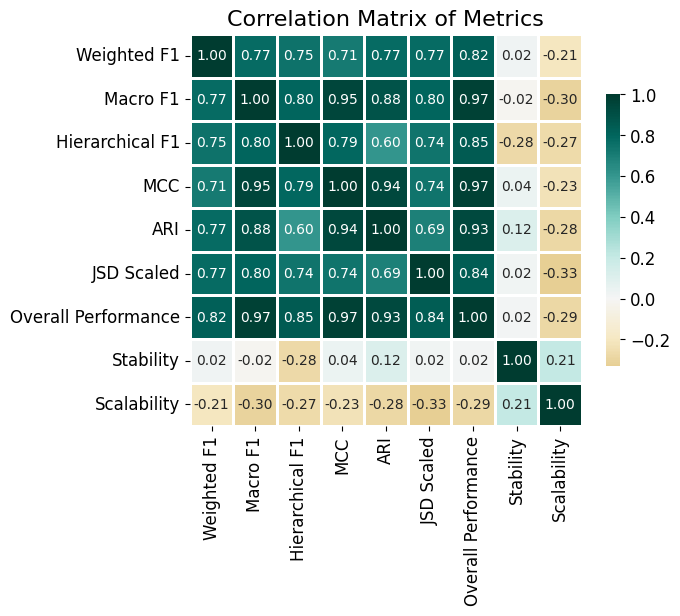

In [39]:
# pruned results to only include the relevant metrics
# get a correlation matrix of the metrics
metrics = ["f1_weighted_mean", 'macro_f1_mean', "hierarchical_f1_mean","mcc_mean","ari_mean", "jsd_scaled_mean",'weighted_score',
                                            "stability", "scalability"]
data = results[metrics].copy()
data = data.rename(columns={
    "f1_weighted_mean": "Weighted F1",
    "hierarchical_f1_mean": "Hierarchical F1",
    "macro_f1_mean": "Macro F1",
    "mcc_mean": "MCC",
    "ari_mean": "ARI",
    "jsd_scaled_mean": "JSD Scaled",
    "stability": "Stability",
    "scalability": "Scalability",
    "weighted_score": "Overall Performance"
})

correlation_matrix = data.corr()
plt.figure(figsize=(7, 7))
ax = sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="BrBG",
    square=True,
    cbar_kws={"shrink": .5},  # removed 'center' which is not a valid argument
    annot_kws={"size": 10},
    linewidths=.75,
    center=0
)
plt.title("Correlation Matrix of Metrics", fontsize=16)
plt.xticks(rotation=90, fontsize=12)
plt.yticks(rotation=0, fontsize=12)
# Set colorbar font size
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=12)
plt.tight_layout()
plt.savefig(os.path.join(output_path, "correlation_matrix_metrics.svg"), dpi=300)
plt.show()

## Heatmaps on perfromances/metrics

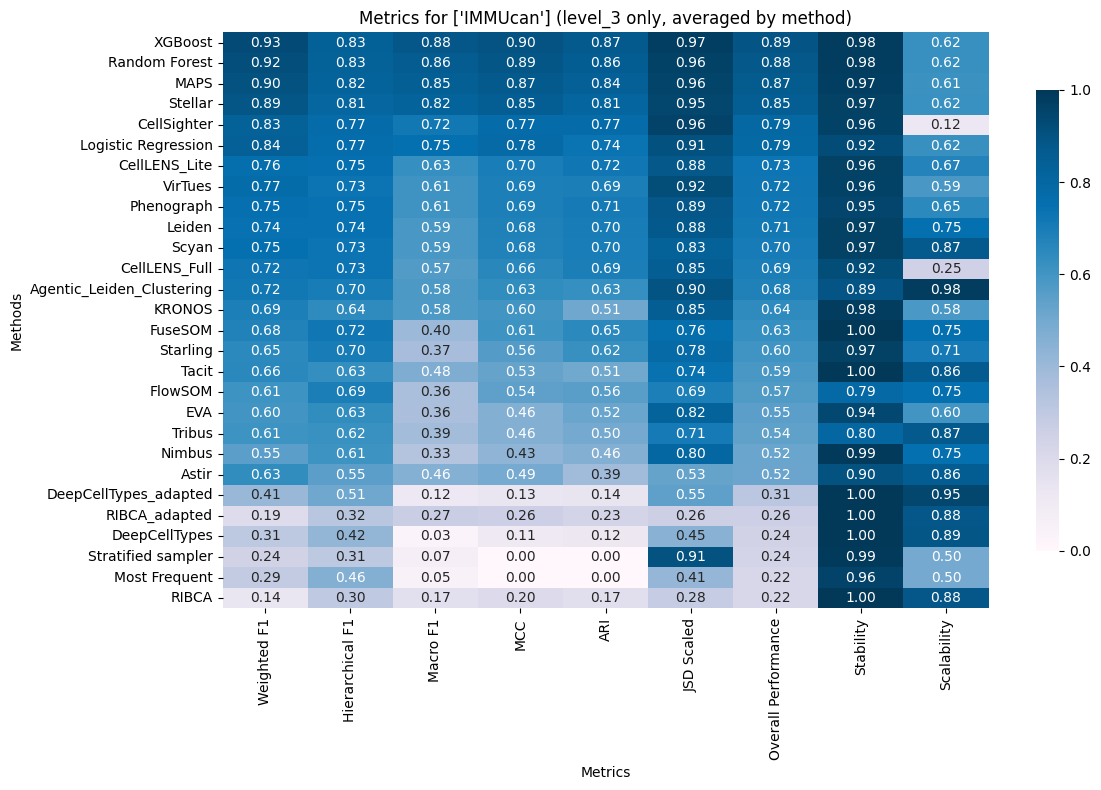

In [40]:
dataset = ["IMMUcan"] # specify the dataset to visualize
metrics = ["Weighted F1", "Hierarchical F1", "Macro F1", "MCC", "ARI", "JSD Scaled",
           "Overall Performance", "Stability", "Scalability"]

# take mean of the metrics for each method for level_3 of the selected dataset
df = results2[(results2["level"] == "level3") & (results2["dataset"].isin(dataset))]
df = df.set_index("method")[metrics]

# Sort by Overall Performance descending, then by method name to ensure consistent order even if Overall Performance is not unique
df = df.sort_values(["Overall Performance"], ascending=[False])

plt.figure(figsize=(12, 8))
sns.heatmap(df, annot=True, fmt=".2f", cmap="PuBu", cbar_kws={"shrink": .8})
plt.title(f"Metrics for {dataset} (level_3 only, averaged by method)")
plt.xlabel("Metrics")
plt.ylabel("Methods")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

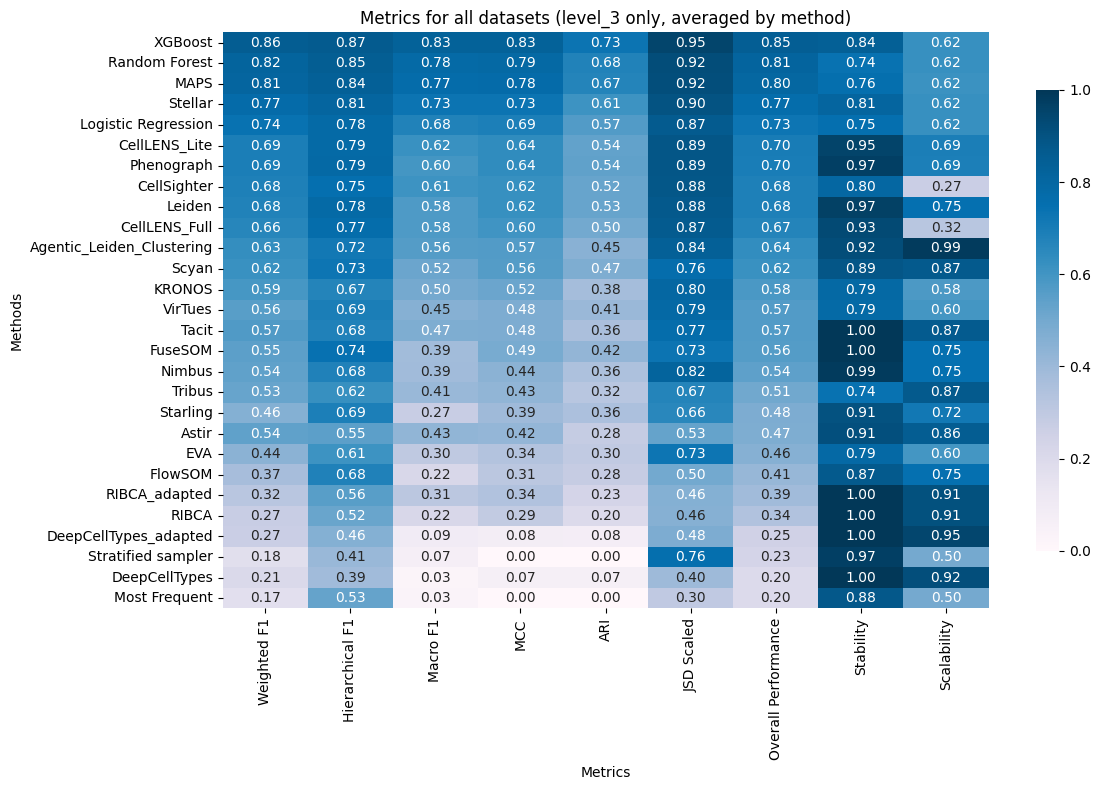

In [41]:
metrics = ["Weighted F1", "Hierarchical F1", "Macro F1", "MCC", "ARI", "JSD Scaled",
           "Overall Performance", "Stability", "Scalability"]

# take mean of the metrics for each method for all datasets
df = results2[results2["level"] == "level3"].groupby("method")[metrics].mean()

# Sort by Overall Performance descending, then by method name to ensure consistent order even if Overall Performance is not unique
df = df.sort_values(["Overall Performance"], ascending=[False])

plt.figure(figsize=(12, 8))
sns.heatmap(df, annot=True, fmt=".2f", cmap="PuBu", cbar_kws={"shrink": .8})
plt.title("Metrics for all datasets (level_3 only, averaged by method)")
plt.xlabel("Metrics")
plt.ylabel("Methods")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [42]:
# save average results for the funkyheatmap
df.to_csv("../final_results/final_results_averaged.csv", sep=",")

In [ ]:
df

## Minimal cell types results

In [43]:
min_results = []
for dataset in datasets:
    df = pd.read_csv(os.path.join(base_path, dataset, "minimal_results.csv"), sep=";")
    df["dataset"] = dataset
    min_results.append(df)

min_results = pd.concat(min_results, ignore_index=True)
min_results = min_results[~min_results["method"].isin(excluded_methods)]
min_results["method"] = min_results["method"].replace(method_rename)
# rename the methods to be more readable
min_results["train_time_mean"] = min_results["train_time_mean"].fillna(0)
min_results["train_time_mean"] = np.where(min_results["train_time_mean"] == min_results["inference_time_mean"], 0, min_results["train_time_mean"])
min_results["run_time"] = min_results["train_time_mean"] + min_results["inference_time_mean"]

# scale run_time to be between 0 and 1 with a threshold
runtime_thresh = 28800 # 8 hours
min_results["runtime_scaled"] = 1 - min_results['run_time'] / runtime_thresh
min_results.loc[min_results['runtime_scaled'] < 0, 'runtime_scaled'] = 0

In [45]:
min_results["level"] = min_results["level"].str.replace("level_", "level")


In [46]:
min_results = min_results[~min_results['method'].str.contains("subclust")]

In [47]:
## re-calculate weighted overall score

# Metric categories and their sub-metrics with weights
metrics_wt = {
    "Classification Performance": {
        "f1_weighted_mean": 0.16,
        "hierarchical_f1_mean": 0.24,
        "macro_f1_mean": 0.2,
        "mcc_mean": 0.2,
    },
    "Cell Type Composition": {
        "ari_mean": 0.08,
        "jsd_scaled_mean": 0.12
    }
}

# calculate the weighted score from the metrics present in the row, weights renormalised to sum to 1
# (hierarchical_f1_mean is NaN for level1/level2)
def calculate_weighted_score(row, metrics_wt):
    weights = {m: w for metrics in metrics_wt.values() for m, w in metrics.items() if pd.notna(row.get(m))}
    return sum(row[m] * w for m, w in weights.items()) / sum(weights.values())

# Apply the weighted score calculation
mask_l3 = min_results['level'] == 'level3'
min_results.loc[mask_l3, 'weighted_score'] = min_results.apply(lambda row: calculate_weighted_score(row, metrics_wt), axis=1)

In [48]:
mask_l3 = min_results['level'] == 'level3'
mask_l1_l2 = min_results['level'].isin(['level1', 'level2'])

#min_results.loc[mask_l3, 'weighted_score'] = min_results.loc[mask_l3, metrics_for_l3].mean(axis=1)
#min_results.loc[mask_l1_l2, 'weighted_score'] = min_results.loc[mask_l1_l2, metrics_for_l1_l2].mean(axis=1)

In [49]:
# apply scaling_scores to the results dataframe
min_results["scaling_score"] = min_results["method"].map(scaling_scores)
# scalability as a mean of the scaling_scores and the runtime_scaled
min_results["scalability"] = (min_results["scaling_score"] + min_results["runtime_scaled"]) / 2
# check rows where method is 'pehnograph_' or 'leiden_' and 
phenograph_rows = min_results[min_results["method"].str.startswith("phenograph_")]
leiden_rows = min_results[min_results["method"].str.startswith("leiden_")]
nimbus_rows = min_results[min_results["method"].str.startswith("nimbus_")]

# take the row with the highest value for overall score
phenograph_best = phenograph_rows.loc[phenograph_rows["weighted_score"].idxmax()]
leiden_best = leiden_rows.loc[leiden_rows["weighted_score"].idxmax()]
nimbus_best = nimbus_rows.loc[nimbus_rows["weighted_score"].idxmax()]

#take the name of the best phenograph and leiden methods
phenograph_best_name = phenograph_best["method"]
leiden_best_name = leiden_best["method"]
nimbus_best_name = nimbus_best["method"]

# keep only the best phenograph and leiden methods in the phenograph_rows and leiden_rows
phenograph_rows = phenograph_rows[phenograph_rows["method"] == phenograph_best_name]
leiden_rows = leiden_rows[leiden_rows["method"] == leiden_best_name]
nimbus_rows = nimbus_rows[nimbus_rows["method"] == nimbus_best_name]

# remove "FlowSOM" from the dataframe
min_results = min_results[~min_results["method"].isin(["FlowSOM"])]


#from results remove phenograph and leiden rows and add the best rows
min_results = min_results[~min_results["method"].str.startswith("phenograph_")]
min_results = min_results[~min_results["method"].str.startswith("leiden_")]
min_results = min_results[~min_results["method"].str.startswith("nimbus_")]
min_results = pd.concat([min_results, phenograph_rows, leiden_rows, nimbus_rows], ignore_index=True)
overall_results_min = min_results[["method", "level", "weighted_score", "dataset"]]
overall_results_min = overall_results_min[overall_results_min['level'] == 'level3']
overall_min = overall_results_min.pivot_table(index="method", columns=["dataset", "level"], values="weighted_score")
overall_min =  overall_min.sort_values(by=list(overall_min.columns), ascending=False)
overall_min.rename(columns={"IMMUcan": "IMMUcan_min", 'cHL_2_MIBI': 'cHL_2_MIBI_min'}, inplace=True)
overall_results = results[["method", "level", "weighted_score", "dataset"]]
overall_results = overall_results[overall_results['level'] == 'level3']
overall_pivot = overall_results.pivot_table(index="method", columns=["dataset", "level"], values="weighted_score")
overall_pivot = overall_pivot.sort_values(by=list(overall_pivot.columns), ascending=False)
merge = pd.merge(overall_pivot, overall_min, on="method", how="inner")
col_order = ['IMMUcan', 'IMMUcan_min', 'cHL_2_MIBI', 'cHL_2_MIBI_min']
merge = merge[col_order]
sorted_by_average_min = merge.loc[merge.mean(axis=1).sort_values(ascending=False).index]

/tmp/ipykernel_3060134/2147298930.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  min_results["scaling_score"] = min_results["method"].map(scaling_scores)
/tmp/ipykernel_3060134/2147298930.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  min_results["scalability"] = (min_results["scaling_score"] + min_results["runtime_scaled"]) / 2


In [ ]:
sorted_by_average_min

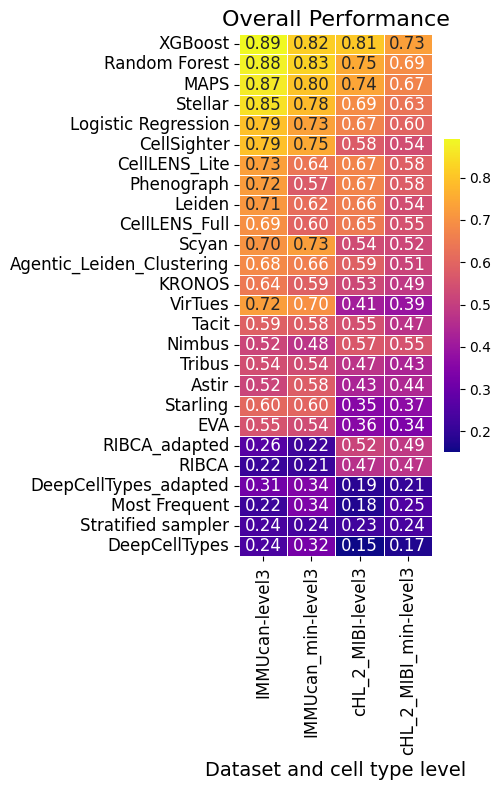

In [50]:
plt.figure(figsize=(5, 8))
sns.heatmap(sorted_by_average_min.iloc[:, :4], annot=True, fmt=".2f", cmap="plasma",
            cbar_kws={"shrink": .6}, linewidths=.6, annot_kws={"size": 12})


# Add your titles and labels
plt.title("Overall Performance", fontsize=16)
plt.xlabel("Dataset and cell type level", fontsize=14)
plt.xticks(fontsize=12, rotation=90)
plt.ylabel("")
plt.yticks(fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(output_path, "overall_performance_minimal_cell_types.svg"), dpi=300)

In [51]:
merge['IMMUcan_diff'] = merge['IMMUcan'] - merge['IMMUcan_min']
merge['cHL_2_MIBI_diff'] = merge['cHL_2_MIBI'] - merge['cHL_2_MIBI_min']

cols = merge.columns[-2:]
sorted_by_average_min = merge.loc[merge[cols].abs().mean(axis=1).sort_values(ascending=False).index]

mask = np.zeros_like(sorted_by_average_min, dtype=bool)
mask[:, :-2] = True

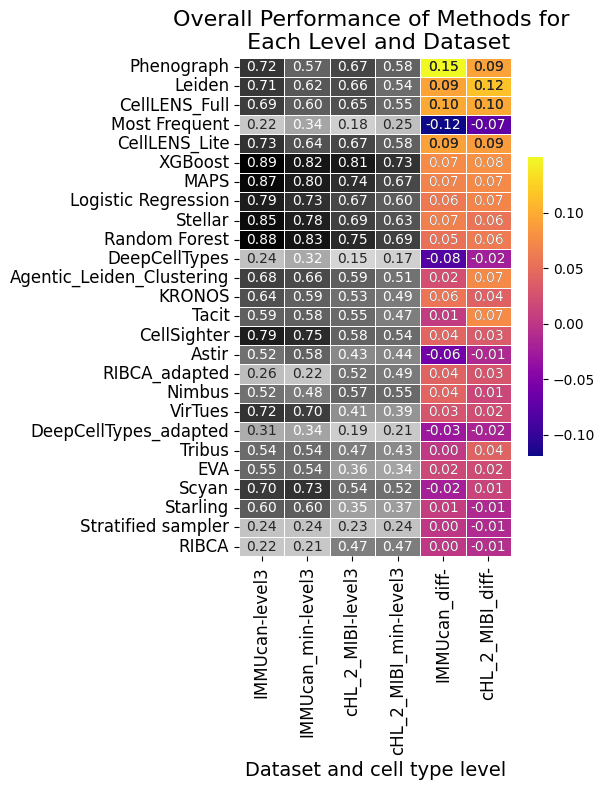

In [52]:
# plot a heatmap of the overall performance of each method for each level for each dataset sepaarated
plt.figure(figsize=(6, 8))
sns.heatmap(sorted_by_average_min, annot=True, fmt=".2f", cmap="Greys",
            cbar=False, linewidths=.6, annot_kws={"size": 10})

# Now, overlay the second heatmap for the specific columns.
# We use the mask to only draw the last two columns.
# The `plasma` colormap is applied here, and a new color bar is drawn for it.
sns.heatmap(sorted_by_average_min, annot=True, fmt=".2f", mask=mask, cmap="plasma",
            cbar_kws={"shrink": .6}, linewidths=.6, annot_kws={"size": 10})


# Add your titles and labels
plt.title("Overall Performance of Methods for \n Each Level and Dataset", fontsize=16)
plt.xlabel("Dataset and cell type level", fontsize=14)
plt.xticks(fontsize=12, rotation=90)
plt.ylabel("")
plt.yticks(fontsize=12)
plt.tight_layout()

# Save the figure if you want
plt.savefig(os.path.join(output_path, "partially_colored_heatmap.svg"), dpi=300)

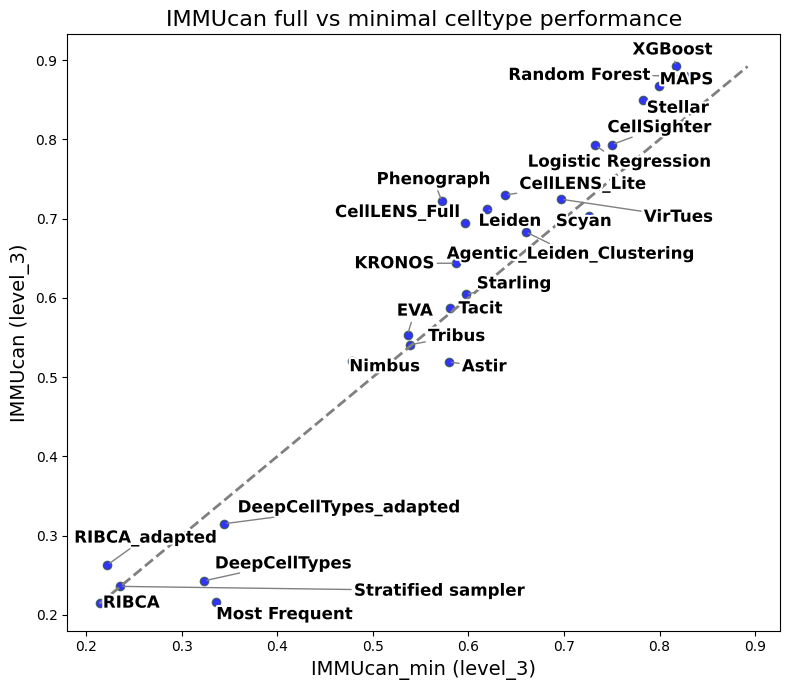

In [53]:
from adjustText import adjust_text
import matplotlib.patheffects as patheffects

fig, ax = plt.subplots(figsize=(8, 7))

x = sorted_by_average_min[('IMMUcan_min', 'level3')]
y = sorted_by_average_min[('IMMUcan', 'level3')]

ax.scatter(x, y, color='blue', edgecolor='darkslategrey', linewidth=1, alpha=0.8)

# Annotate each point with the method name, larger and bold, with white outline
texts = []
for method in x.index:
    texts.append(
        ax.text(
            x[method], y[method], method,
            fontsize=12, fontweight='bold',
            color='black',
            path_effects=[patheffects.withStroke(linewidth=3, foreground='white')]
        )
    )

# Adjust text to avoid overlap
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='gray'))

# Add diagonal line
min_val = min(x.min(), y.min())
max_val = max(x.max(), y.max())
ax.plot([min_val, max_val], [min_val, max_val], color='gray', linestyle='--', linewidth=2)

ax.set_xlabel('IMMUcan_min (level_3)', fontsize=14)
ax.set_ylabel('IMMUcan (level_3)', fontsize=14)
ax.set_title('IMMUcan full vs minimal celltype performance', fontsize=16)
plt.tight_layout()

# save as svg
#plt.savefig("minimal_results_scatter.svg")
plt.savefig(os.path.join(output_path, "minimal_results_immucan.svg"), bbox_inches='tight', dpi=300)
plt.show()

## Heatmap with overall over all levels

In [54]:
# get the overall performance of each method for each level
overall_results = results2[["method", "level", "Overall Performance", "dataset"]]
overall_results

,method,level,Overall Performance,dataset
0,Agentic_Leiden_Clustering,level1,0.514533,cHL_2_MIBI
1,Agentic_Leiden_Clustering,level2,0.647017,cHL_2_MIBI
2,Agentic_Leiden_Clustering,level3,0.588300,cHL_2_MIBI
3,Astir,level1,0.353152,cHL_2_MIBI
4,Astir,level2,0.394166,cHL_2_MIBI
...,...,...,...,...
163,FuseSOM,level3,0.500748,cHL_2_MIBI
164,FlowSOM,level3,0.249945,cHL_2_MIBI
165,Leiden,level3,0.655143,cHL_2_MIBI
166,Nimbus,level3,0.566077,cHL_2_MIBI


In [55]:
# pivot table for overall performance of each method for each level
overall_pivot = overall_results.pivot_table(index="method", columns=["dataset", "level"], values="Overall Performance")
overall_pivot = overall_pivot.sort_values(by=list(overall_pivot.columns), ascending=False)
overall_pivot

dataset                     IMMUcan                     cHL_2_MIBI            \
level                        level1    level2    level3     level1    level2   
method                                                                         
XGBoost                    0.924073  0.920998  0.892058   0.657645  0.830640   
Random Forest              0.914835  0.911116  0.879945   0.630032  0.789596   
MAPS                       0.901855  0.898272  0.867500   0.791045  0.777060   
Stellar                    0.883084  0.879309  0.849600   0.732200  0.716749   
CellSighter                0.841615  0.832864  0.793221   0.508289  0.607968   
Logistic Regression        0.833043  0.823475  0.792541   0.569469  0.703777   
VirTues                    0.786871  0.772271  0.724421   0.539149  0.495233   
Phenograph                 0.783183  0.773245  0.722139   0.602725  0.741735   
CellLENS_Lite              0.780890  0.773021  0.729963   0.600370  0.719826   
Leiden                     0.776362  0.766351  0.712388   0.598628  0.732929   
CellLENS_Full              0.755041  0.742464  0.694500   0.582660  0.694874   
Starling                   0.752227  0.737758  0.604364   0.382762  0.427385   
Agentic_Leiden_Clustering  0.736660  0.729743  0.683319   0.514533  0.647017   
Scyan                      0.736543  0.730873  0.703905   0.496939  0.562325   
FuseSOM                    0.711911  0.699345  0.626787   0.503633  0.613936   
KRONOS                     0.694415  0.681566  0.643643   0.573437  0.569746   
EVA                        0.680173  0.634194  0.553440   0.463862  0.435714   
Tacit                      0.668330  0.637137  0.586684   0.530450  0.613734   
FlowSOM                    0.664583  0.645499  0.573283   0.357046  0.276251   
Tribus                     0.636533  0.608098  0.540837   0.487991  0.472725   
Nimbus                     0.593592  0.566347  0.520584   0.497834  0.612309   
Astir                      0.495286  0.501608  0.519025   0.353152  0.394166   
DeepCellTypes_adapted      0.438004  0.365297  0.314874   0.290936  0.264493   
DeepCellTypes              0.308927  0.242139  0.242864   0.237312  0.207418   
Stratified sampler         0.297584  0.266999  0.235854   0.325573  0.252281   
RIBCA_adapted              0.227202  0.257626  0.262880   0.479184  0.583418   
RIBCA                      0.203253  0.227270  0.215318   0.418364  0.508733   
Most Frequent              0.168265  0.159959  0.216018   0.351630  0.177653   

dataset                              
level                        level3  
method                               
XGBoost                    0.807152  
Random Forest              0.749858  
MAPS                       0.740854  
Stellar                    0.688136  
CellSighter                0.575278  
Logistic Regression        0.666937  
VirTues                    0.412348  
Phenograph                 0.671651  
CellLENS_Lite              0.672107  
Leiden                     0.655143  
CellLENS_Full              0.646782  
Starling                   0.354647  
Agentic_Leiden_Clustering  0.588300  
Scyan                      0.535327  
FuseSOM                    0.500748  
KRONOS                     0.525559  
EVA                        0.358736  
Tacit                      0.546583  
FlowSOM                    0.249945  
Tribus                     0.474135  
Nimbus                     0.566077  
Astir                      0.430758  
DeepCellTypes_adapted      0.186916  
DeepCellTypes              0.151972  
Stratified sampler         0.226288  
RIBCA_adapted              0.515316  
RIBCA                      0.466335  
Most Frequent              0.177410

In [56]:
sorted_by_average = overall_pivot.loc[overall_pivot.mean(axis=1).sort_values(ascending=False).index]
sorted_by_average

dataset                     IMMUcan                     cHL_2_MIBI            \
level                        level1    level2    level3     level1    level2   
method                                                                         
XGBoost                    0.924073  0.920998  0.892058   0.657645  0.830640   
MAPS                       0.901855  0.898272  0.867500   0.791045  0.777060   
Random Forest              0.914835  0.911116  0.879945   0.630032  0.789596   
Stellar                    0.883084  0.879309  0.849600   0.732200  0.716749   
Logistic Regression        0.833043  0.823475  0.792541   0.569469  0.703777   
Phenograph                 0.783183  0.773245  0.722139   0.602725  0.741735   
CellLENS_Lite              0.780890  0.773021  0.729963   0.600370  0.719826   
Leiden                     0.776362  0.766351  0.712388   0.598628  0.732929   
CellSighter                0.841615  0.832864  0.793221   0.508289  0.607968   
CellLENS_Full              0.755041  0.742464  0.694500   0.582660  0.694874   
Agentic_Leiden_Clustering  0.736660  0.729743  0.683319   0.514533  0.647017   
Scyan                      0.736543  0.730873  0.703905   0.496939  0.562325   
VirTues                    0.786871  0.772271  0.724421   0.539149  0.495233   
KRONOS                     0.694415  0.681566  0.643643   0.573437  0.569746   
FuseSOM                    0.711911  0.699345  0.626787   0.503633  0.613936   
Tacit                      0.668330  0.637137  0.586684   0.530450  0.613734   
Nimbus                     0.593592  0.566347  0.520584   0.497834  0.612309   
Starling                   0.752227  0.737758  0.604364   0.382762  0.427385   
Tribus                     0.636533  0.608098  0.540837   0.487991  0.472725   
EVA                        0.680173  0.634194  0.553440   0.463862  0.435714   
FlowSOM                    0.664583  0.645499  0.573283   0.357046  0.276251   
Astir                      0.495286  0.501608  0.519025   0.353152  0.394166   
RIBCA_adapted              0.227202  0.257626  0.262880   0.479184  0.583418   
RIBCA                      0.203253  0.227270  0.215318   0.418364  0.508733   
DeepCellTypes_adapted      0.438004  0.365297  0.314874   0.290936  0.264493   
Stratified sampler         0.297584  0.266999  0.235854   0.325573  0.252281   
DeepCellTypes              0.308927  0.242139  0.242864   0.237312  0.207418   
Most Frequent              0.168265  0.159959  0.216018   0.351630  0.177653   

dataset                              
level                        level3  
method                               
XGBoost                    0.807152  
MAPS                       0.740854  
Random Forest              0.749858  
Stellar                    0.688136  
Logistic Regression        0.666937  
Phenograph                 0.671651  
CellLENS_Lite              0.672107  
Leiden                     0.655143  
CellSighter                0.575278  
CellLENS_Full              0.646782  
Agentic_Leiden_Clustering  0.588300  
Scyan                      0.535327  
VirTues                    0.412348  
KRONOS                     0.525559  
FuseSOM                    0.500748  
Tacit                      0.546583  
Nimbus                     0.566077  
Starling                   0.354647  
Tribus                     0.474135  
EVA                        0.358736  
FlowSOM                    0.249945  
Astir                      0.430758  
RIBCA_adapted              0.515316  
RIBCA                      0.466335  
DeepCellTypes_adapted      0.186916  
Stratified sampler         0.226288  
DeepCellTypes              0.151972  
Most Frequent              0.177410

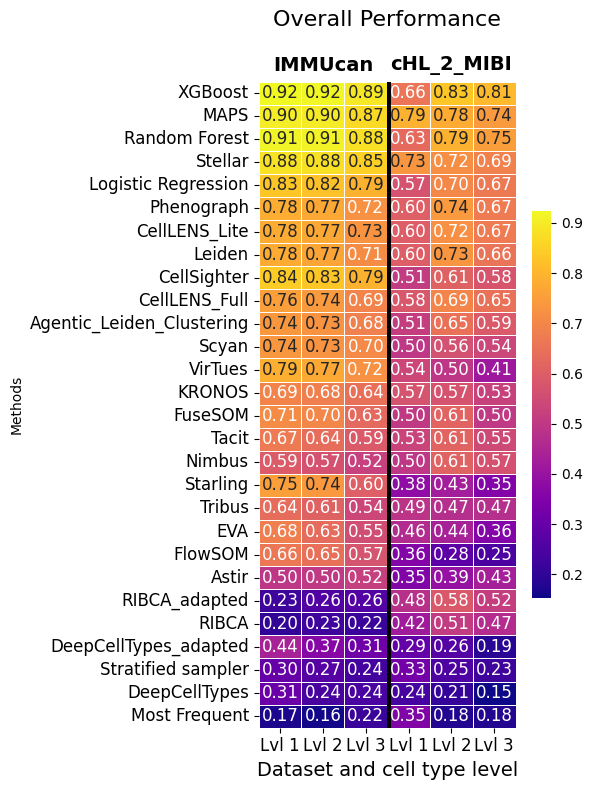

In [58]:
# Prepare custom x-tick labels
datasets = ["IMMUcan", "cHL_2_MIBI"]
levels = ["level1", "level2", "level3"]
xtick_labels = [f"Lvl {lvl.removeprefix('level')}" for ds in datasets for lvl in levels]

# Prepare dataset labels for the second row
dataset_labels = []
for ds in datasets:
    dataset_labels.extend([ds] * len(levels))

plt.figure(figsize=(6, 8))
ax = sns.heatmap(
    sorted_by_average,
    annot=True,
    fmt=".2f",
    cmap="plasma",
    cbar_kws={"shrink": .6},
    annot_kws={"size": 12},
    linewidths=.6
)
plt.title("Overall Performance", fontsize=16, pad=40)
plt.xlabel("Dataset and cell type level", fontsize=14)
plt.ylabel("Methods")

# Set the top row (levels)
ax.set_xticks(np.arange(len(xtick_labels)) + 0.5)
ax.set_xticklabels(xtick_labels, fontsize=12, rotation=0, ha='center')

# Add the bottom row (datasets)
for i, ds in enumerate(datasets):
    xpos = i * len(levels) + 1.5
    ax.text(xpos, -0.7, ds, fontsize=14, ha='center', va='center', fontweight='bold', color='black')

plt.yticks(fontsize=12)

# Add white vertical gap between datasets
gap_col = len(levels)  # index after first dataset
ax.add_patch(plt.Rectangle((gap_col, 0), 0.10, sorted_by_average.shape[0], color='black', zorder=10, linewidth=0))

plt.tight_layout()
plt.savefig(os.path.join(output_path, "overall_performance_heatmap_granularities.svg"), dpi=300)
plt.show()

## Overall bar-plot performances over all methods and datasets

In [59]:
overall_performance = results.groupby("method")["weighted_score"].mean().sort_values(ascending=False).reset_index()
overall_performance

,method,weighted_score
0,XGBoost,0.838761
1,MAPS,0.829431
2,Random Forest,0.812563
3,Stellar,0.791513
4,Logistic Regression,0.731540
5,Phenograph,0.715780
6,CellLENS_Lite,0.712696
7,Leiden,0.706967
8,CellSighter,0.693206
9,CellLENS_Full,0.686053


In [61]:
# Prepare method group mapping for each method
method_to_group = {}
for group, methods in method_groups.items():
    for m in methods:
        method_to_group[m] = group

# Use readable names from method_rename
method_to_group.update({method_rename.get(k, k): v for k, v in method_to_group.items()})

# Create a DataFrame for plotting
plot_df = overall_performance.reset_index()
plot_df["group"] = plot_df["method"].map(method_to_group).fillna("Other")

# Sort by group, then by score
plot_df = plot_df.sort_values(["group", "weighted_score"], ascending=[True, False])

# # Add horizontal dotted lines for baselines
# baseline_scores = plot_df[plot_df["group"] == "baselines"]["overall_score"]
# for score in baseline_scores:
#     plt.axhline(y=score, color='gray', linestyle='--', linewidth=0.8)
    
# plt.figure(figsize=(14, 7))
# sns.barplot(x="method", y="overall_score", hue="group", data=plot_df, dodge=False, palette="gist_earth")
# plt.title("Overall Performance of Each Method Across All Datasets (Grouped)")
# plt.xlabel("Method")
# plt.ylabel("Overall Score")
# plt.xticks(rotation=45, ha='right')
# plt.legend(title="Method Group", bbox_to_anchor=(1.05, 1), loc='upper left')
# plt.tight_layout()
# plt.show()

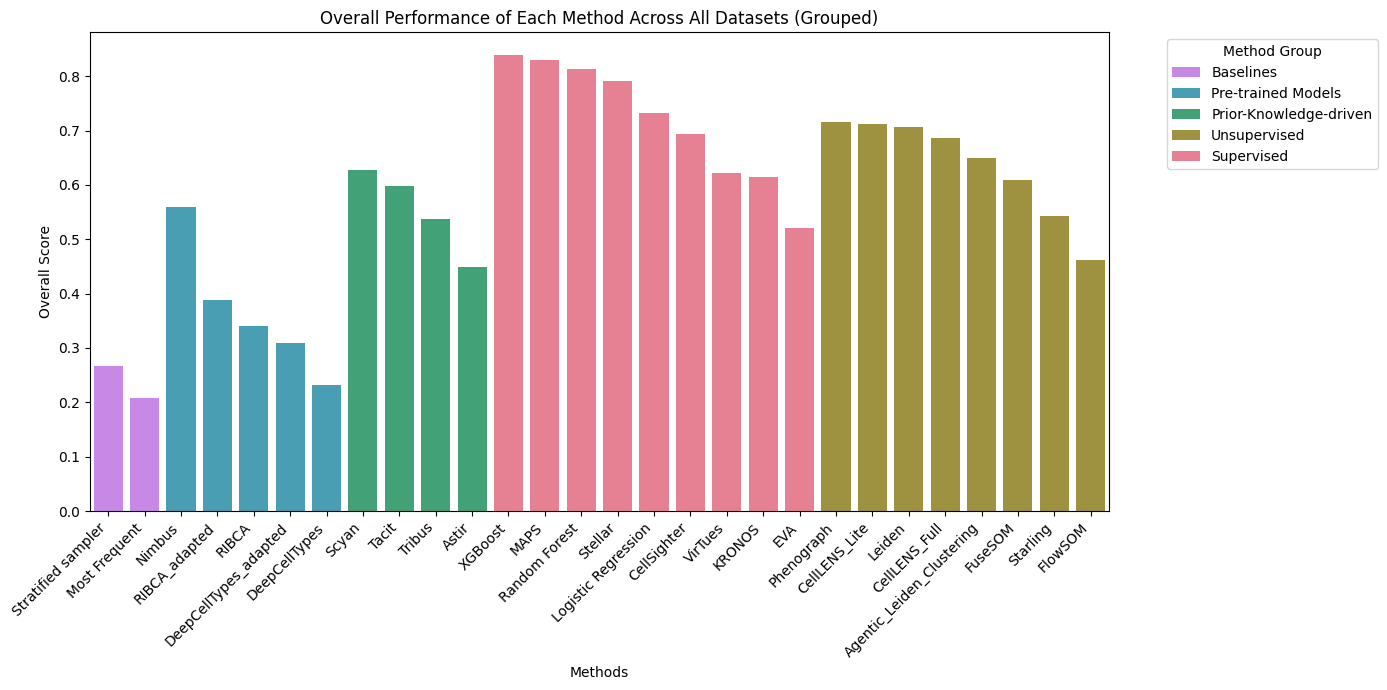

In [62]:
# Compute mean overall_score per group
group_order = plot_df.groupby("group")["weighted_score"].mean().sort_values(ascending=True).index.tolist()

plt.figure(figsize=(14, 7))
ax = sns.barplot(
    x="method",
    y="weighted_score",
    hue="group",
    data=plot_df,
    dodge=False,
    palette=method_cmap,
    hue_order=group_order
)

# Add horizontal dotted lines for baselines
baseline_scores = plot_df[plot_df["group"] == "baselines"]["weighted_score"]
for score in baseline_scores:
    plt.axhline(score, color="gray", linestyle=":", linewidth=2, alpha=0.7)

plt.title("Overall Performance of Each Method Across All Datasets (Grouped)")
plt.xlabel("Methods")
plt.ylabel("Overall Score")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Method Group", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


## Overall Rank Chart

In [ ]:
results2

In [68]:
#take rows where level is level_3
results_lvl3 = results2[results2["level"] == "level3"]
# pivot dataset and overall score
rank_results = results_lvl3.pivot(index=["method"], columns="dataset", values=["Overall Performance"])
# keep only the dataset name as the column name
rank_results.columns = rank_results.columns.droplevel(0)

rank_results['avg_score'] = rank_results.mean(axis=1)
#rank_results['rank'] = rank_results['avg_score'].rank(ascending=False, method='min')
rank_results

dataset,IMMUcan,cHL_2_MIBI,avg_score
method,,,
Agentic_Leiden_Clustering,0.683319,0.588300,0.635809
Astir,0.519025,0.430758,0.474891
CellLENS_Full,0.694500,0.646782,0.670641
CellLENS_Lite,0.729963,0.672107,0.701035
CellSighter,0.793221,0.575278,0.684249
DeepCellTypes,0.242864,0.151972,0.197418
DeepCellTypes_adapted,0.314874,0.186916,0.250895
EVA,0.553440,0.358736,0.456088
FlowSOM,0.573283,0.249945,0.411614


In [69]:
# Compute ranks (higher score = higher rank number = drawn at the top; the bump chart's rank axis is inverted)
rank_df = rank_results.rank(ascending=True, axis=0)
rank_columns = rank_df.columns
methods = rank_df.index

# Sort methods by mean rank
rank_df = rank_df.loc[rank_df.mean(axis=1).sort_values().index]

In [70]:
rank_df

dataset,IMMUcan,cHL_2_MIBI,avg_score
method,,,
Most Frequent,2.0,2.0,1.0
DeepCellTypes,4.0,1.0,2.0
Stratified sampler,3.0,4.0,3.0
DeepCellTypes_adapted,6.0,3.0,4.0
RIBCA,1.0,10.0,5.0
FlowSOM,11.0,5.0,7.0
RIBCA_adapted,5.0,13.0,6.0
Astir,7.0,9.0,9.0
EVA,10.0,7.0,8.0


In [71]:
def draw_curve(ax, x1, y1, x2, y2, color, linewidth=12, alpha=1):
    verts = [
        (x1, y1),                # Start point
        ((x1 + x2) / 2, y1),     # Control point 1
        ((x1 + x2) / 2, y2),     # Control point 2
        (x2, y2)                 # End point
    ]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4]
    path = Path(verts, codes)
    patch = PathPatch(path, facecolor='none', edgecolor=color, lw=linewidth, alpha=alpha)
    ax.add_patch(patch)

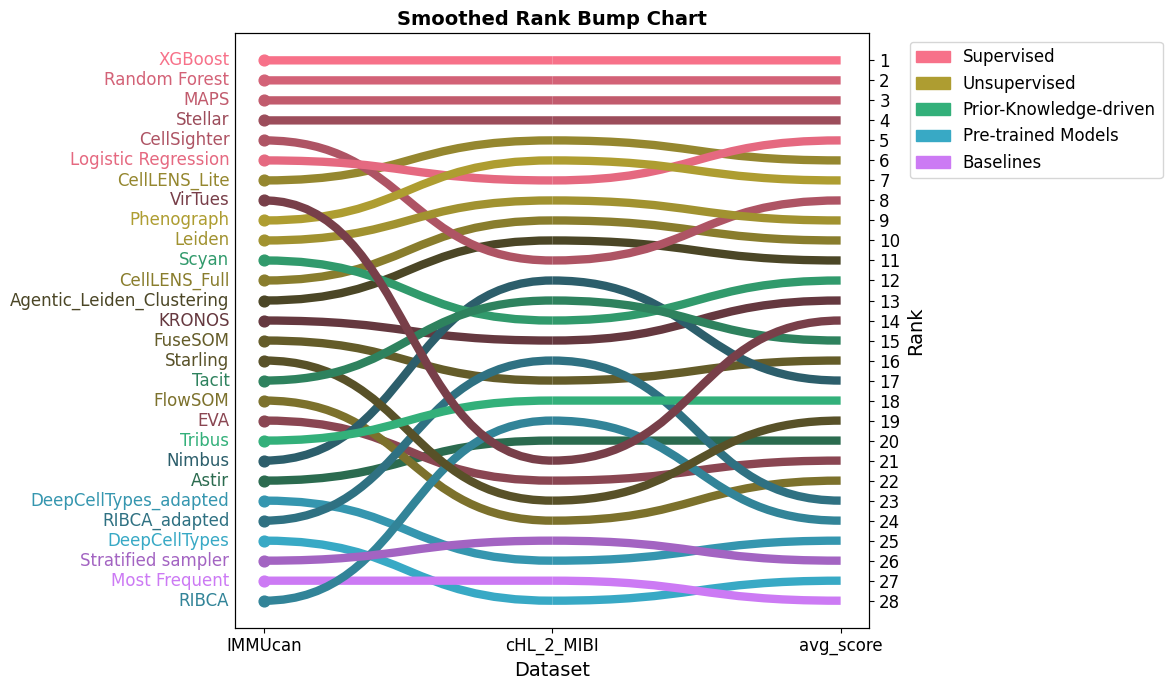

In [72]:
method_colors = {}
for group, methods_in_group in method_groups.items():
    base_color = method_cmap[group]
    
    # Create a palette starting with the base color and getting darker
    # input="rgb" ensures seaborn interprets your tuple correctly
    num_methods = len(methods_in_group)
    
    palette = sns.dark_palette(base_color, n_colors=num_methods + 3, reverse=True, input="rgb")

    for i, method in enumerate(methods_in_group):
        # Assign colors sequentially from the generated palette
        color = palette[i]
        method_colors[method] = mcolors.to_hex(color)
fig, ax = plt.subplots(figsize=(12, 7))

x_vals = np.arange(len(rank_columns))

for method in methods:
    y = rank_df.loc[method].values
    color = method_colors[method]

    # Draw smooth curves between each dataset
    for i in range(len(x_vals) - 1):
        draw_curve(ax, x_vals[i], y[i], x_vals[i+1], y[i+1], color=color, linewidth=6)

    # Start and end dots
    ax.scatter(x_vals[0], y[0], color=color, s=60, zorder=2)
    ax.text(x_vals[0] - 0.12, y[0], method, ha='right', va='center', color=color, fontsize=12)

# Right y-axis: rank labels
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
ax2.set_yticks(range(1, len(rank_df) + 1))
ax2.set_yticklabels(range(1, len(rank_df) + 1), fontsize=12)
ax2.set_ylabel("Rank", fontsize=14)
ax2.invert_yaxis()

# Style
ax.set_yticks([])
ax.set_ylabel("")
ax.tick_params(axis='y', left=False)
ax.set_xticks(x_vals)
ax.set_xticklabels(rank_columns, rotation=0, ha='center', fontsize=12)
ax.set_xlabel("Dataset", fontsize=14)
ax.set_title("Smoothed Rank Bump Chart", fontsize=14, weight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.3)

# Add legend for method groups
legend_handles = []
for group, color in method_cmap.items():
    legend_handles.append(mpatches.Patch(color=to_hex(color), label=group))
ax.legend(handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=12)

plt.tight_layout()
fig.savefig(os.path.join(output_path, "smoothed_rank_bump_chart.svg"), format='svg', bbox_inches='tight')
plt.show()


## Hierarcheal F1 score

In [73]:
# get the hierarchy mappings from the qt files
qt_path = "../all_qt"
qt_files = [f for f in os.listdir(qt_path) if f.endswith(".csv")]

hierarchy_mappings = {}
conflicts = []

for qt_file in qt_files:
    qt_df = pd.read_csv(os.path.join(qt_path, qt_file))

    # keep only required columns and normalize strings
    subset_df = qt_df[["cell_type", "level_2_cell_type", "level_1_cell_type"]].copy()
    subset_df = subset_df.dropna(subset=["cell_type"])
    for col in ["cell_type", "level_2_cell_type", "level_1_cell_type"]:
        subset_df[col] = subset_df[col].astype(str).str.strip()

    # remove exact duplicate rows, then force unique index by cell_type
    subset_df = subset_df.drop_duplicates()
    unique_df = subset_df.groupby("cell_type", as_index=True)[
        ["level_2_cell_type", "level_1_cell_type"]
    ].first()

    mapping = unique_df.to_dict(orient="index")

    # merge into global mapping; keep first mapping if conflicts appear
    for ct, vals in mapping.items():
        if ct in hierarchy_mappings and hierarchy_mappings[ct] != vals:
            conflicts.append((ct, hierarchy_mappings[ct], vals, qt_file))
            continue
        hierarchy_mappings[ct] = vals

# save the hierarchy mappings to a file
with open("hierarchy_mappings.pkl", "wb") as f:
    import pickle
    pickle.dump(hierarchy_mappings, f)

# read the hierarchy mappings from the file
with open("hierarchy_mappings.pkl", "rb") as f:
    import pickle
    hierarchy_mappings = pickle.load(f)

print(f"Mapped {len(hierarchy_mappings)} unique cell types.")
if conflicts:
    print(f"Found {len(conflicts)} cross-file conflicts (kept first occurrence).")

Mapped 61 unique cell types.
Found 4 cross-file conflicts (kept first occurrence).


In [74]:
#read the hierarchy mappings from the file
with open('hierarchy_mappings.pkl', 'rb') as f:
    import pickle
    hierarchy_mappings = pickle.load(f)

In [75]:
def build_tree(mapping: Dict[str, Dict[str, str]]) -> Dict:
    tree = defaultdict(lambda: defaultdict(list))
    for leaf, levels in mapping.items():
        level1 = levels['level_1_cell_type']
        level2 = levels['level_2_cell_type']
        tree[level1][level2].append(leaf)
    return tree

# Convert tree to indented text view
def tree_to_text(tree: Dict, indent: int = 0) -> str:
    lines = []
    for level1, sublevels in tree.items():
        lines.append('  ' * indent + level1)
        for level2, leaves in sublevels.items():
            lines.append('  ' * (indent + 1) + level2)
            for leaf in leaves:
                lines.append('  ' * (indent + 2) + leaf)
    return '\n'.join(lines)

# Create the tree and save it to a txt file
tree = build_tree(hierarchy_mappings)
tree_text = tree_to_text(tree)

# Save to a text file
file_path = "cell_type_hierarchy3.txt"
with open(file_path, "w") as f:
    f.write(tree_text)

In [79]:
def parse_tree_file(file_path: str) -> dict:
    """Parses a 2-space-indented tree file and returns label -> ancestor path mapping."""
    with open(file_path, 'r') as f:
        lines = f.readlines()

    label_to_ancestors = {}
    path_stack = []

    for line in lines:
        stripped = line.lstrip()
        indent = len(line) - len(stripped)
        level = indent // 2  # Assumes 2 spaces per indent

        path_stack = path_stack[:level]
        path_stack.append(stripped.strip())

        if level >= 2:
            label = path_stack[-1]
            label_to_ancestors[label] = path_stack[:-1]  # from root to parent

    return label_to_ancestors

In [80]:
file_path = "cell_type_hierarchy3.txt"
ancestor_map = parse_tree_file(file_path)

## Dataset distributions

In [85]:
def parse_tree_levels(file_path):
    # Parse the indented tree file and return (parent, child) pairs for all levels
    with open(file_path, "r") as f:
        lines = f.readlines()

    pairs = []
    stack = []

    for line in lines:
        stripped = line.lstrip()
        node = stripped.strip()
        if not node:
            continue

        indent = len(line) - len(stripped)
        level = indent // 2

        stack = stack[:level]
        stack.append(node)

        if level > 0:
            parent = stack[-2]
            child = stack[-1]
            if parent != child:  # remove self loops
                pairs.append((parent, child))

    return pairs


def generate_sankey_from_tree(file_path, order=None):
    pairs = parse_tree_levels(file_path)

    # Keep first-seen node order from file
    nodes_in_pairs = list(dict.fromkeys([n for pair in pairs for n in pair]))

    # If order list is provided, use it first, then append remaining nodes
    if order is None:
        node_labels = nodes_in_pairs
    else:
        node_labels = [n for n in order if n in nodes_in_pairs] + [
            n for n in nodes_in_pairs if n not in order
        ]

    label_to_idx = {label: i for i, label in enumerate(node_labels)}

    source = [label_to_idx[pair[0]] for pair in pairs]
    target = [label_to_idx[pair[1]] for pair in pairs]
    value = [1] * len(pairs)

    fig = go.Figure(
        data=[
            go.Sankey(
                node=dict(
                    pad=15,
                    thickness=20,
                    line=dict(color="black", width=0.5),
                    label=node_labels,
                ),
                link=dict(
                    source=source,
                    target=target,
                    value=value,
                ),
            )
        ]
    )

    fig.update_layout(
        title_text="Cell Type Hierarchy Sankey Diagram (All Levels)",
        font_size=10,
        width=800,
        height=1000,
    )
    fig.show()

generate_sankey_from_tree(file_path)


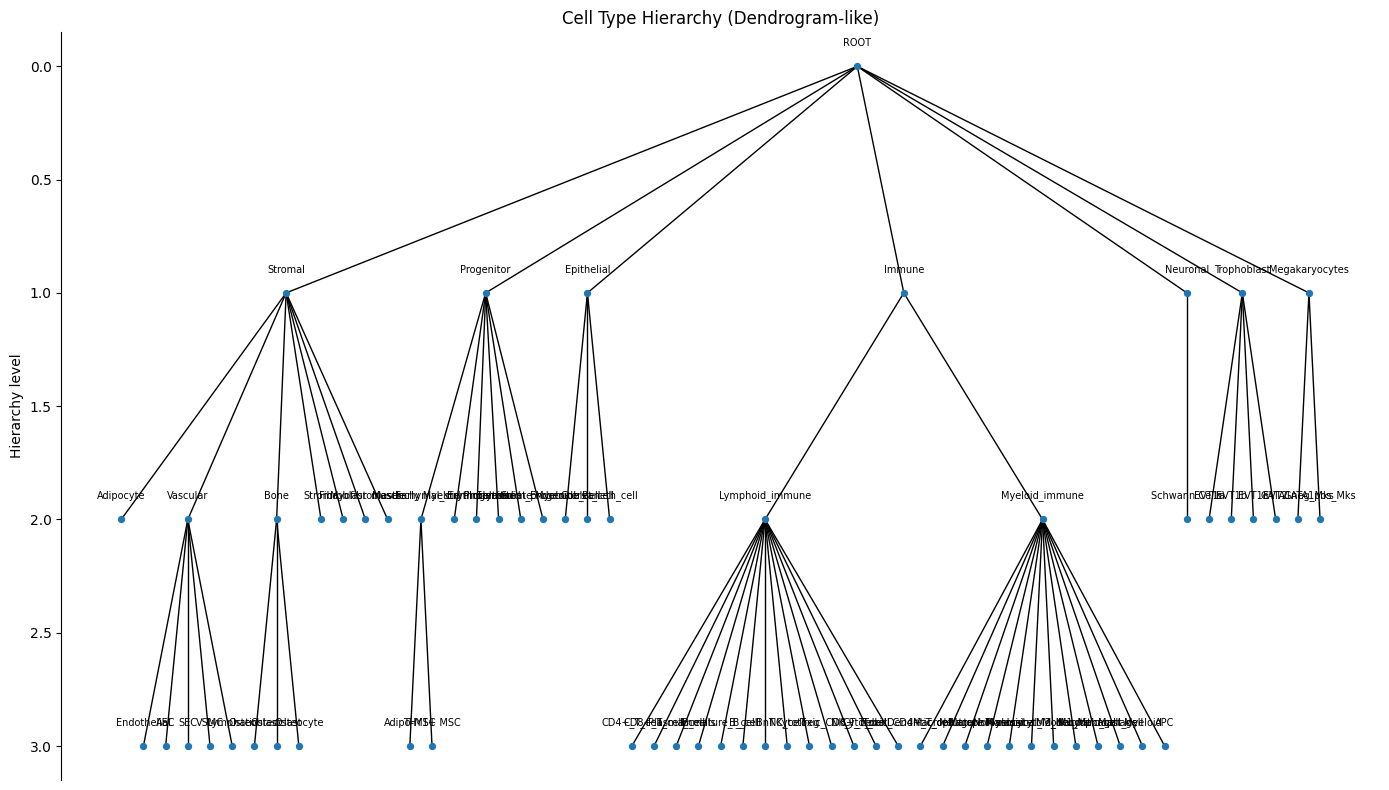

In [86]:
# from the cell_type_hierarchy.txt file, plot a dendogram-like tree
pairs = parse_tree_levels(file_path)

# Build parent -> children structure
children = defaultdict(list)
parent_of = {}
nodes = set()

for p, c in pairs:
    children[p].append(c)
    parent_of[c] = p
    nodes.update([p, c])

# Root detection
roots = [n for n in nodes if n not in parent_of]
if len(roots) == 0:
    raise ValueError("No root found in hierarchy file.")
if len(roots) > 1:
    # create a virtual root if multiple roots exist
    virtual_root = "ROOT"
    children[virtual_root] = roots
    for r in roots:
        parent_of[r] = virtual_root
    root = virtual_root
    nodes.add(virtual_root)
else:
    root = roots[0]

# Depth (y) assignment
depth = {}
stack = [(root, 0)]
while stack:
    node, d = stack.pop()
    depth[node] = d
    for ch in children.get(node, []):
        stack.append((ch, d + 1))

# X assignment: leaves from left->right, internal nodes centered over children
xpos = {}
leaf_x = [0]

def assign_x(node):
    ch = children.get(node, [])
    if len(ch) == 0:
        xpos[node] = leaf_x[0]
        leaf_x[0] += 1
    else:
        for c in ch:
            assign_x(c)
        xpos[node] = np.mean([xpos[c] for c in ch])

assign_x(root)

# Plot
fig, ax = plt.subplots(figsize=(14, 8))

# Edges
for p, ch_list in children.items():
    for c in ch_list:
        ax.plot([xpos[p], xpos[c]], [depth[p], depth[c]], color="black", lw=1)

# Nodes + labels
for n in nodes:
    ax.scatter(xpos[n], depth[n], s=18, color="#1f77b4", zorder=3)
    ax.text(xpos[n], depth[n] - 0.08, n, ha="center", va="bottom", fontsize=7)

ax.set_title("Cell Type Hierarchy (Dendrogram-like)")
ax.set_xticks([])
ax.set_ylabel("Hierarchy level")
ax.invert_yaxis()  # root on top
ax.spines[['top', 'right', 'bottom']].set_visible(False)
plt.tight_layout()
plt.show()


In [83]:
def parse_tree_for_sunburst(file_path):
    # Parse the indented tree file and return names and parents for sunburst
    names = []
    parents = []
    stack = []
    with open(file_path, 'r') as f:
        for line in f:
            stripped = line.lstrip()
            indent = len(line) - len(stripped)
            level = indent // 2
            name = stripped.strip()
            if not name:
                continue
            if level == 0:
                parent = ""
            else:
                parent = stack[level - 1]
            if name not in names:  # avoid duplicates
                names.append(name)
                parents.append(parent)
            if len(stack) <= level:
                stack.append(name)
            else:
                stack[level] = name

    return names, parents

def generate_radial_tree(file_path):
    names, parents = parse_tree_for_sunburst(file_path)
    fig = px.sunburst(
        names=names,
        parents=parents,
        width=1000,
        height=800,
        maxdepth=6,
        color_discrete_sequence=px.colors.qualitative.T10
    )

    fig.update_layout(
                        margin=dict(t=10, l=10, r=10, b=10)
                     )

    fig.show()

    fig.write_html(os.path.join(output_path, "sunburst_distribution_all.html"))
    fig.write_image(os.path.join(output_path, "sunburst_distribution_all.svg"))

generate_radial_tree(file_path)

RuntimeError: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"


## Metric accumulation

In [87]:
#rename id col to method
results_lvl3 = results_lvl3.rename(columns={"id": "method"})

In [88]:
# get methods and results[metrics] in a dataframe
results_cat = results_lvl3.set_index('method')
results_cat = results_cat[metrics]
# take mean of each metric by method
results_cat = results_cat.groupby(results_cat.index).mean()
results_cat

,Weighted F1,Hierarchical F1,Macro F1,MCC,ARI,JSD Scaled,Overall Performance,Stability,Scalability
method,,,,,,,,,
Agentic_Leiden_Clustering,0.630461,0.718432,0.562500,0.569190,0.446718,0.836968,0.635809,0.921703,0.987975
Astir,0.540685,0.550344,0.429633,0.420975,0.282387,0.529890,0.474891,0.913475,0.856551
CellLENS_Full,0.663447,0.766730,0.577881,0.602908,0.503529,0.866948,0.670641,0.931366,0.321598
CellLENS_Lite,0.693384,0.785093,0.620894,0.638947,0.537616,0.889114,0.701035,0.954262,0.692393
CellSighter,0.684711,0.750913,0.609490,0.622571,0.524018,0.884523,0.684249,0.799952,0.268670
DeepCellTypes,0.205550,0.388284,0.025556,0.066237,0.066188,0.397397,0.197418,1.000000,0.917879
DeepCellTypes_adapted,0.268449,0.457817,0.091715,0.079898,0.076427,0.480251,0.250895,1.000000,0.947198
EVA,0.442086,0.610268,0.301631,0.337060,0.296170,0.728816,0.456088,0.788634,0.596361
FlowSOM,0.371526,0.681700,0.216361,0.314726,0.279233,0.500049,0.411614,0.874721,0.749135


/tmp/ipykernel_3060134/1315850975.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Set2", n_metrics)  # will generate n_metrics colors


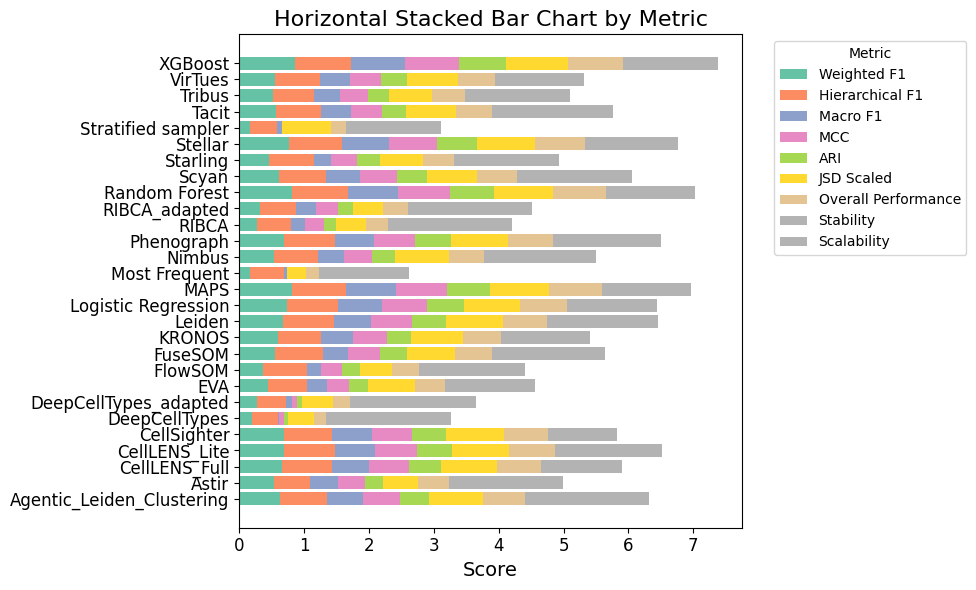

In [89]:
df = results_cat

# Check column count
n_metrics = len(df.columns)

# Choose a colormap with enough colors
from matplotlib.cm import get_cmap
cmap = get_cmap("Set2", n_metrics)  # will generate n_metrics colors
colors = [cmap(i) for i in range(n_metrics)]

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
left = [0] * len(df)

# Plot each metric as a segment
for i, col in enumerate(df.columns):
    ax.barh(df.index, df[col], left=left, label=col, color=colors[i])
    left = [l + v for l, v in zip(left, df[col])]

# Aesthetics
ax.set_xlabel("Score", fontsize=14)
ax.set_title("Horizontal Stacked Bar Chart by Metric", fontsize=16)
ax.legend(title="Metric", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3060134/3399861881.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Set2", n_metrics)


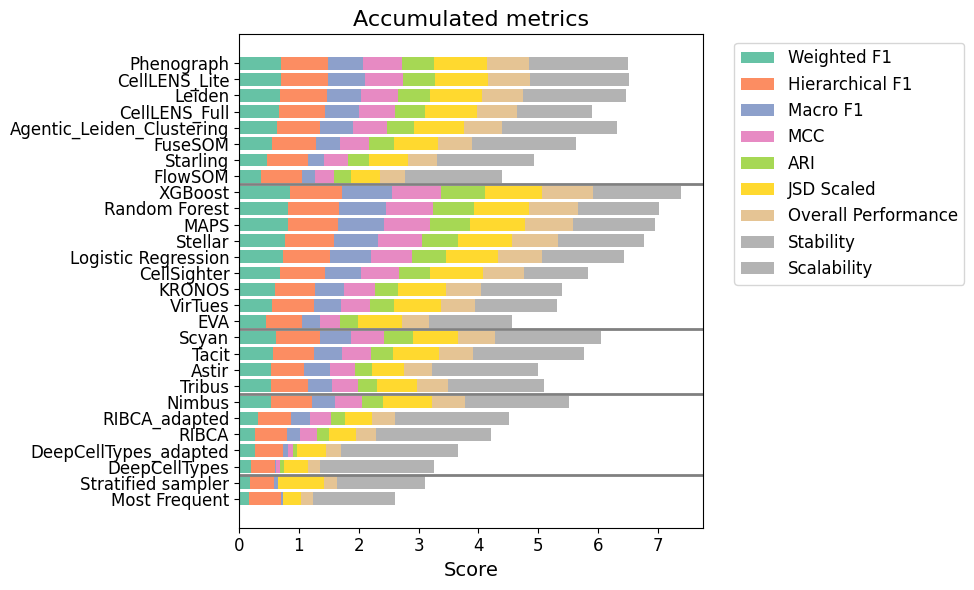

In [90]:
# Step 2: Make method → group mapping
method_to_group = {method: group for group, methods in method_groups.items() for method in methods}

# Step 3: Add group to your DataFrame
df['group'] = df.index.map(method_to_group)

# Step 4: Sort by group (and optionally by method name within group)
df_sorted = df.sort_values(by=['group', df.columns[0]])  # replace columns[0] with a metric name if needed

# Step 5: Plot horizontal stacked bar
metrics = [col for col in df_sorted.columns if col != 'group']
n_metrics = len(metrics)

# Generate distinct colors per metric
cmap = get_cmap("Set2", n_metrics)
colors = [cmap(i) for i in range(n_metrics)]

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
left = [0] * len(df_sorted)

for i, col in enumerate(metrics):
    ax.barh(df_sorted.index, df_sorted[col], left=left, label=col, color=colors[i])
    left = [l + v for l, v in zip(left, df_sorted[col])]

# Get the numeric y positions of each method
y_positions = range(len(df_sorted))

# Track the last seen group
last_group = None
for i, (idx, row) in enumerate(df_sorted.iterrows()):
    current_group = row['group']
    if last_group is not None and current_group != last_group:
        # Draw a dotted line between groups
        ax.axhline(i - 0.5, color='gray', linestyle='-', linewidth=2)
    last_group = current_group

# Aesthetics
ax.set_xlabel("Score", fontsize=14)
ax.set_title("Accumulated metrics", fontsize=16)
ax.legend(title="", bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(output_path, "accumulated_metrics.svg"), dpi=300)
plt.show()

## Performance vs scalability/stability

In [91]:
df = pd.read_csv('../final_results/final_results_averaged.csv', sep=',').set_index('method')
df['Method_group'] = df.index.map(method_to_group)

In [ ]:
df

In [92]:
df["Scalability/Stability"] = (df["Scalability"] + df["Stability"]) / 2
fig = px.scatter(df, x="Scalability/Stability", y="Overall Performance", color="Method_group",
                 size='Macro F1', hover_data=[df.index,'Overall Performance', 'Scalability/Stability', 'Macro F1'],)

fig.update_layout(
    font=dict(
        size=12,           # Default font size for all text
    ),
    xaxis=dict(
        title_font=dict(size=14),   # X-axis title font size
        tickfont=dict(size=12),     # X-axis tick label font size
    ),
    yaxis=dict(
        title_font=dict(size=14),   # Y-axis title font size
        tickfont=dict(size=12),     # Y-axis tick label font size
    ),
    title_font=dict(size=16),       # Title font size
    legend=dict(
        font=dict(size=12),         # Legend font size
        title_font=dict(size=14),   # Legend title font size
    )
)

fig.update_layout(width=600, height=370)

fig.update_layout(
    template='simple_white',
    title="Performance vs Scalability/Stability",
    xaxis=dict(title="Scalability/Stability", range=[0.45, 1]),
    #xaxis=dict(title="Scalability/Stability"),
    yaxis=dict(title="Performance Overall")
)
fig.update_traces(marker=dict(line=dict(width=1, color='DarkSlateGrey')))

fig.show()

fig.write_html(os.path.join(output_path, "scatter_plot_grouped.html"))

# save as svg
fig.write_image(os.path.join(output_path, "scatter_plot_grouped.svg"), width=800, height=600, scale=2)

RuntimeError: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"


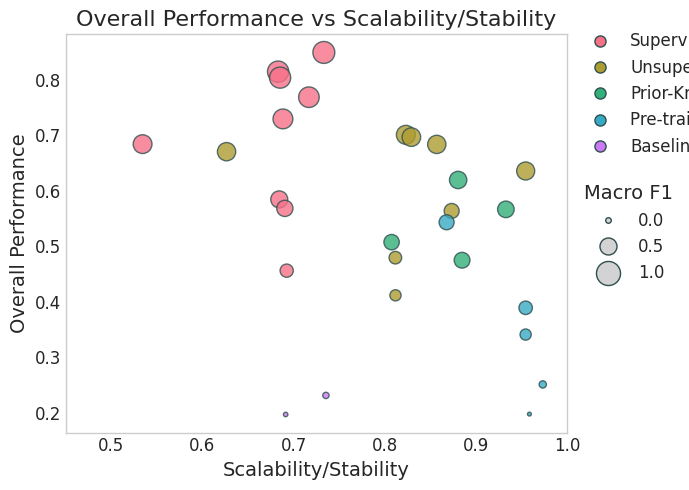

In [93]:

# Use the correct seaborn style depending on matplotlib version
methodologies = df["Method_group"].unique()
available_styles = plt.style.available
if 'seaborn-whitegrid' in available_styles:
    plt.style.use('seaborn-whitegrid')
elif 'seaborn-v0_8-whitegrid' in available_styles:
    plt.style.use('seaborn-v0_8-whitegrid')
else:
    plt.style.use('default')

fig, ax = plt.subplots(figsize=(7, 5))

# Scatter plot points
for method in methodologies:
    subset = df[df["Method_group"] == method]
    ax.scatter(
        subset["Scalability/Stability"],
        subset["Overall Performance"],
        s=subset["Macro F1"] * 300,  # scaled size
        color=method_cmap[method],
        edgecolor='darkslategrey',
        linewidth=1,
        alpha=0.8
    )

# ---------- Legend 1: Methodology colors ----------
color_handles = [
    plt.Line2D(
        [0], [0],
        marker='o',
        color='w',
        label=method,
        markerfacecolor=method_cmap[method],
        markeredgecolor='darkslategrey',
        markersize=8
    )
    for method in methodologies
]
legend1 = ax.legend(
    handles=color_handles,
    title="",
    title_fontsize=14,
    fontsize=12,
    loc='center left',
    bbox_to_anchor=(1.02, 0.85),
    borderaxespad=0
)
legend1._legend_title_box._text.set_ha("left")  # align left
ax.add_artist(legend1)

# ---------- Legend 2: Dot size for Macro F1 ----------
# Example size values
size_values = [0, 0.5, 1]
size_handles = [
    plt.Line2D(
        [0], [0],
        marker='o',
        color='w',
        label=f"{v:.1f}",
        markerfacecolor='lightgray',
        markeredgecolor='darkslategrey',
        markersize=np.sqrt(v * 300) if v > 0 else 4  # match scatter scaling
    )
    for v in size_values
]

legend2 = ax.legend(
    handles=size_handles,
    title="Macro F1",
    title_fontsize=14,
    fontsize=12,
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0
)
legend2._legend_title_box._text.set_ha("left")  # align left

# Titles & labels
ax.set_title("Overall Performance vs Scalability/Stability", fontsize=16)
ax.set_xlabel("Scalability/Stability", fontsize=14)
ax.set_ylabel("Overall Performance", fontsize=14)
ax.set_xlim(0.45, 1)
ax.tick_params(axis='both', labelsize=12)

ax.grid(False)

plt.tight_layout()
plt.show()

# save as svg
fig.savefig(os.path.join(output_path, "performance_vs_scalability.svg"), format="svg", bbox_inches="tight")
#fig.savefig("performance_vs_scalability.svg", format="svg", bbox_inches="tight")

## barplot

In [94]:
# take mean of the metrics for each method for all datasets
df = results[results["level"] == "level3"]
#set methods to index
df = df.set_index("method")

# rename the columns to be more readable
df = df.rename(columns={
    "f1_weighted_mean": "Weighted F1",
    "hierarchical_f1_mean": "Hierarchical F1",
    "macro_f1_mean": "Macro F1",
    "mcc_mean": "MCC",
    "ari_mean": "ARI",
    "jsd_scaled_mean": "JSD Scaled",
    "stability": "Stability",
    "scalability": "Scalability",
    "weighted_score": "Overall Performance"
})


# Step 2: Make method → group mapping
method_to_group = {method: group for group, methods in method_groups.items() for method in methods}

df['Method_group'] = df.index.map(method_to_group)

# move the "Overall Performance" to before "Stability" and "Scalability"
df = df[["Weighted F1", "Hierarchical F1", "Macro F1", "MCC", "ARI", "JSD Scaled", 
         "Overall Performance",
         "Stability", "Scalability",
         "Method_group"]]

df

,Weighted F1,Hierarchical F1,Macro F1,MCC,ARI,JSD Scaled,Overall Performance,Stability,Scalability,Method_group
method,,,,,,,,,,
Agentic_Leiden_Clustering,0.544006,0.737051,0.544984,0.503505,0.265668,0.778461,0.588300,0.952594,0.996344,Unsupervised
Astir,0.446390,0.549095,0.401245,0.347341,0.176701,0.530833,0.430758,0.922862,0.857259,Prior-Knowledge-driven
CellSighter,0.540896,0.727790,0.503694,0.471019,0.273499,0.810358,0.575278,0.636101,0.412340,Supervised
DeepCellTypes,0.105539,0.353124,0.018142,0.022256,0.009187,0.346006,0.151972,1.000000,0.947198,Pre-trained Models
DeepCellTypes_adapted,0.127358,0.405794,0.065562,0.026625,0.010777,0.415401,0.186916,1.000000,0.947198,Pre-trained Models
EVA,0.282613,0.587624,0.243359,0.209994,0.069897,0.635209,0.358736,0.636431,0.594927,Supervised
KRONOS,0.492622,0.695220,0.421471,0.432928,0.242063,0.747013,0.525559,0.600351,0.576460,Supervised
Logistic Regression,0.642508,0.800330,0.607095,0.598887,0.401800,0.822634,0.666937,0.580223,0.624964,Supervised
MAPS,0.717114,0.855308,0.696222,0.681838,0.497679,0.878461,0.740854,0.537163,0.616065,Supervised


In [95]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

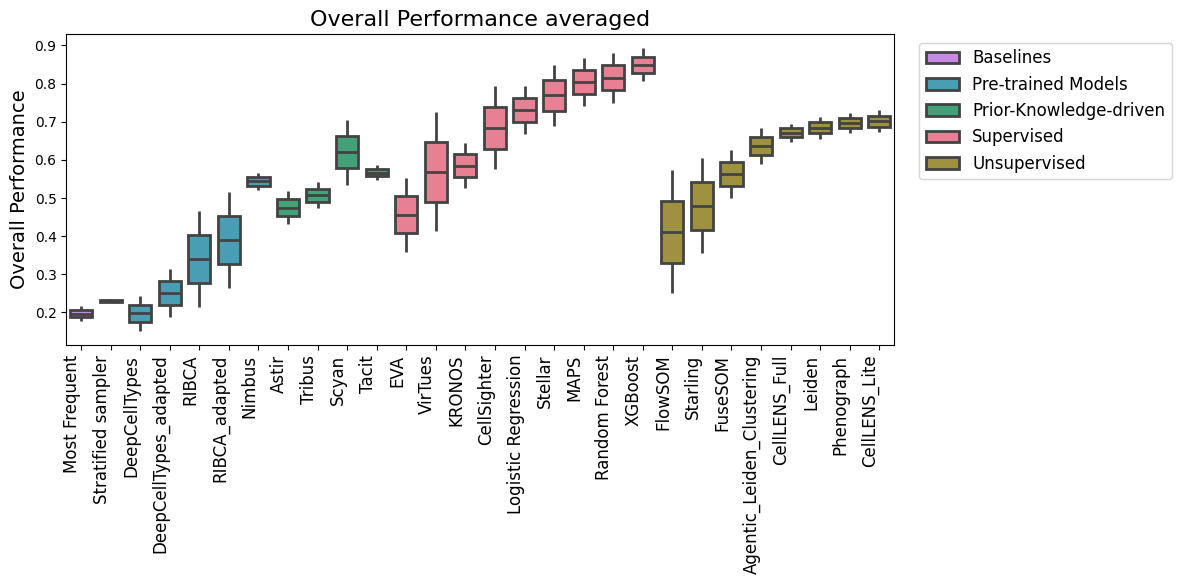

In [96]:
# Sort the dataframe by group and method
df_sorted = df.sort_values(by=["Method_group", "method"])
df_sorted = df_sorted.sort_values(by=['Method_group', 'Overall Performance'], ascending=[True, True])

# Get the order of methods after sorting (includes duplicates)
method_order = df_sorted.index.tolist()

# Use the correct seaborn style depending on matplotlib version
plt.style.use('default')

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_sorted,
    x="method",
    y="Overall Performance",
    hue="Method_group",
    palette=method_cmap,
    dodge=False,
    order=method_order,
    showcaps=False,
    linewidth=2,
    width=0.75
)

# Set font sizes
plt.rcParams.update({'font.size': 12})  # Default font size
plt.xticks(rotation=90, ha='right', fontsize=12)
plt.xlabel('', fontsize=14)
plt.ylabel('Overall Performance', fontsize=14)
plt.title('Overall Performance averaged', fontsize=16)

# Move legend outside the plot with custom font sizes
legend = plt.legend(title="", bbox_to_anchor=(1.02, 1), loc='upper left')
legend.get_title().set_fontsize(14)
for text in legend.get_texts():
    text.set_fontsize(12)

plt.tight_layout()

# save as svg
plt.savefig(os.path.join(output_path, "boxplot_performance_overall.svg"), format='svg', bbox_inches='tight', dpi=300)

plt.show()

## Pareto 

In [ ]:
df

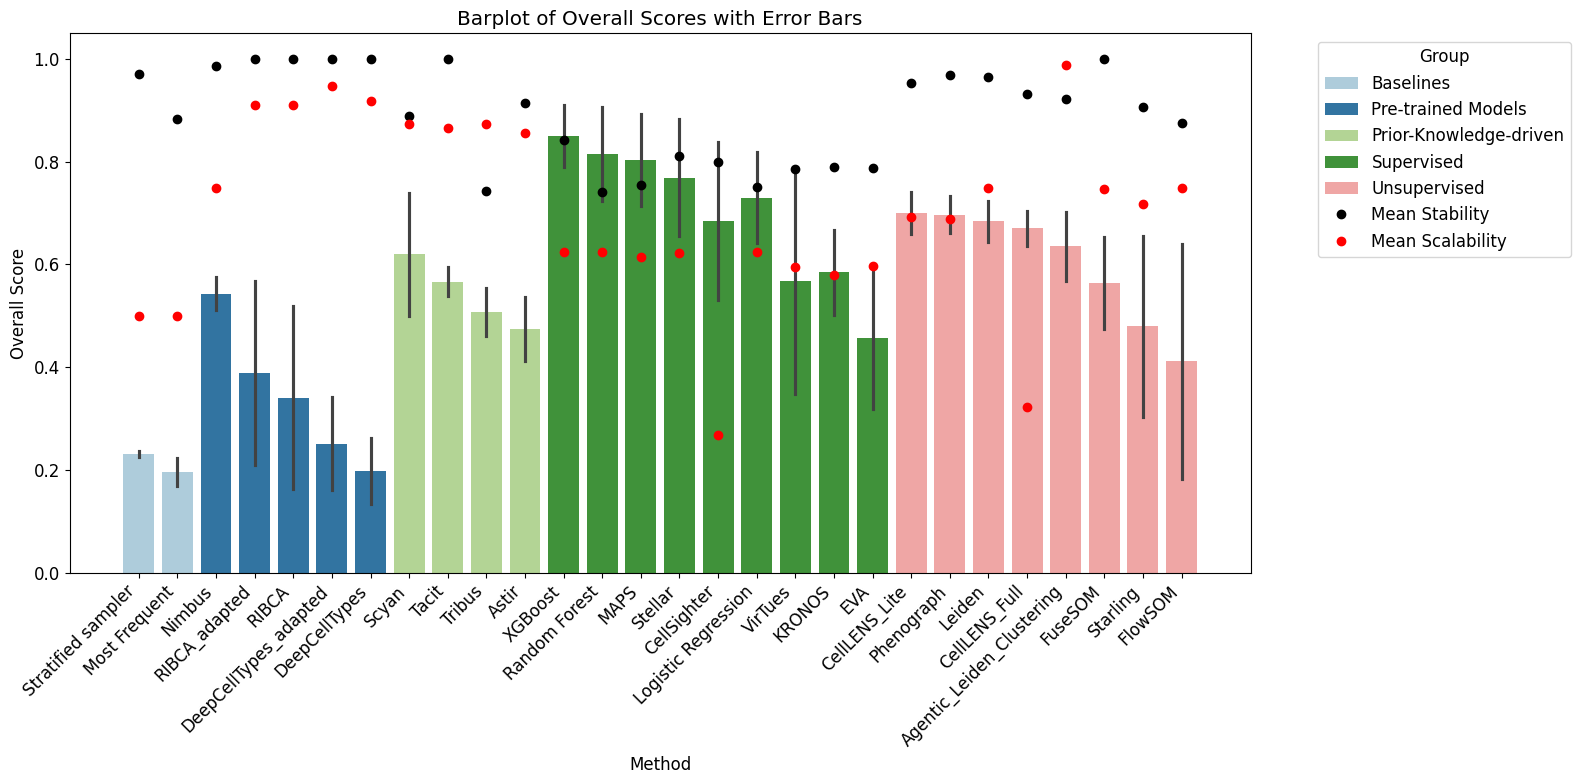

In [97]:
# Sort by scalability (descending)
#df_sorted = df_sorted.sort_values(by="Methodology", ascending=False)

df_sorted = df_sorted.sort_values(by=['Method_group', 'Overall Performance'], ascending=[True, False])  

plt.figure(figsize=(16, 8))
sns.barplot(
    data=df_sorted,
    x="method",
    y="Overall Performance",
    hue="Method_group",
    palette="Paired",
    errorbar="sd",
    order=df_sorted.index.tolist()
)

# calculate mean scalabilty for each method
mean_scalability = df_sorted.groupby("method")["Scalability"].mean().reset_index()
mean_stability = df_sorted.groupby("method")["Stability"].mean().reset_index()


# Add mean stability of each method as dots that are connected by a single line
# Plot mean stability as dots
# Plot mean stability as dots
plt.errorbar(
    x=mean_stability["method"],
    y=mean_stability["Stability"],
    fmt='o',
    color='black',
    label='Mean Stability',
    capsize=5,
)

# Add mean stability of each method as dots that are connected by a single line
plt.errorbar(
    x=mean_stability["method"],
    y=mean_scalability["Scalability"],
    fmt='o',
    color='red',
    label='Mean Scalability',
    capsize=5,
)


# # calculate mean scalabilty for each method
# mean_scalability = df_sorted.groupby("method")["Scalability"].mean().reset_index()
# mean_stability = df_sorted.groupby("method")["Stability"].mean().reset_index()

# # get the unique methods only
# unique_methods = df_sorted.index.unique().tolist()

# #order the mean_scalability and mean_stability by the unique methods
# mean_scalability = mean_scalability[mean_scalability["method"].isin(unique_methods)]
# mean_stability = mean_stability[mean_stability["method"].isin(unique_methods)]  
# # Plot mean scalability as dots and connect them with a line
# plt.plot(mean_scalability.index, mean_scalability["Scalability"], color='red', marker='o', label='Mean Scalability', linewidth=2)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Method')
plt.ylabel('Overall Score')
plt.title('Barplot of Overall Scores with Error Bars')
plt.legend(title="Group", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## scalability plot

In [98]:
scalability_plot_lvl3 = results[results["level"] == "level3"]
scalability_plot_lvl3 = scalability_plot_lvl3[["method", "train_time_mean", "inference_time_mean", "runtime_scaled", "scaling_score", "scalability"]]
scalability_plot_lvl3

,method,train_time_mean,inference_time_mean,runtime_scaled,scaling_score,scalability
2,Agentic_Leiden_Clustering,0.0000,210.610000,0.992687,1.00,0.996344
5,Astir,0.0000,1021.892000,0.964518,0.75,0.857259
8,CellSighter,12114.0000,135.200000,0.574681,0.25,0.412340
11,DeepCellTypes,0.0000,3041.386000,0.894396,1.00,0.947198
14,DeepCellTypes_adapted,0.0000,3041.386000,0.894396,1.00,0.947198
17,EVA,12.8000,1719.422000,0.939853,0.25,0.594927
20,KRONOS,13.4100,2782.506000,0.902920,0.25,0.576460
23,Logistic Regression,2.0400,0.032000,0.999928,0.25,0.624964
26,MAPS,509.2440,5.386000,0.982131,0.25,0.616065
29,Most Frequent,0.0000,0.000000,1.000000,0.00,0.500000


In [99]:
# get the mean by method
scalability_plot_lvl3 = scalability_plot_lvl3.groupby("method").mean().reset_index()
scalability_plot_lvl3

,method,train_time_mean,inference_time_mean,runtime_scaled,scaling_score,scalability
0,Agentic_Leiden_Clustering,0.0000,692.638333,0.975950,1.00,0.987975
1,Astir,0.0000,1062.672000,0.963102,0.75,0.856551
2,CellLENS_Full,31395.5416,0.000000,0.143197,0.50,0.321598
3,CellLENS_Lite,3068.1358,250.036400,0.884786,0.50,0.692393
4,CellSighter,27304.1000,182.900000,0.287340,0.25,0.268670
5,DeepCellTypes,0.0000,4730.145000,0.835759,1.00,0.917879
6,DeepCellTypes_adapted,0.0000,3041.386000,0.894396,1.00,0.947198
7,EVA,19.8450,1629.764000,0.942722,0.25,0.596361
8,FlowSOM,0.0000,49.834600,0.998270,0.50,0.749135
9,FuseSOM,0.0000,158.439000,0.994499,0.50,0.747249


In [100]:
scalability_plot_lvl3 = scalability_plot_lvl3[~scalability_plot_lvl3['method'].str.contains('adapted', case=False, na=False)]
#drop row where method is 'baseline'
scalability_plot_lvl3 = scalability_plot_lvl3[~scalability_plot_lvl3['method'].str.contains('Most Frequent', case=False, na=False)]
scalability_plot_lvl3 = scalability_plot_lvl3[~scalability_plot_lvl3['method'].str.contains('Stratified sampler', case=False, na=False)]

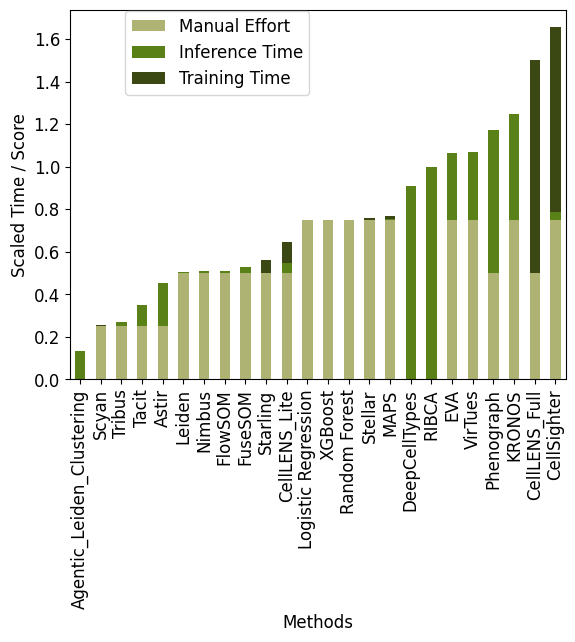

In [102]:
# scale train and inference time to be between 0 and 1 where 0 is fastest and 1 is slowest
inference_thresh = max(scalability_plot_lvl3["inference_time_mean"])
train_thresh = max(scalability_plot_lvl3["train_time_mean"])

scalability_plot_lvl3["train_time_scaled"] = scalability_plot_lvl3["train_time_mean"] / train_thresh
scalability_plot_lvl3["inference_time_scaled"] = scalability_plot_lvl3["inference_time_mean"] / inference_thresh
scalability_plot_lvl3["revised_scaling_score"] = 1 - scalability_plot_lvl3["scaling_score"]

# Calculate total for ordering
scalability_plot_lvl3["total"] = (
    scalability_plot_lvl3["revised_scaling_score"] +
    scalability_plot_lvl3["inference_time_scaled"] +
    scalability_plot_lvl3["train_time_scaled"]
)

# Sort by total (lowest to highest)
scalability_plot_lvl3_sorted = scalability_plot_lvl3.sort_values("total")

colors = [
    "#aeb374",  # green1
    "#598118",  # green2
    "#3b4814",  # green3
]

# plot a stacked barplot with methods in the x axis and train and inference time in the y axis
ax = scalability_plot_lvl3_sorted.plot.bar(
    x="method",
    y=["revised_scaling_score", "inference_time_scaled", "train_time_scaled"],
    stacked=True,
    color=colors
)

# Rename legend labels
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Manual Effort", "Inference Time", "Training Time"], fontsize=12, bbox_to_anchor=(0.5, 1.02), loc='upper right')

plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
plt.xlabel("Methods")
plt.ylabel("Scaled Time / Score")
ax.grid(False)  # Remove grid lines
plt.savefig(os.path.join(output_path, "scalability_plot_lvl3.svg"), format='svg', bbox_inches='tight', dpi=300)


no run time recorded: []


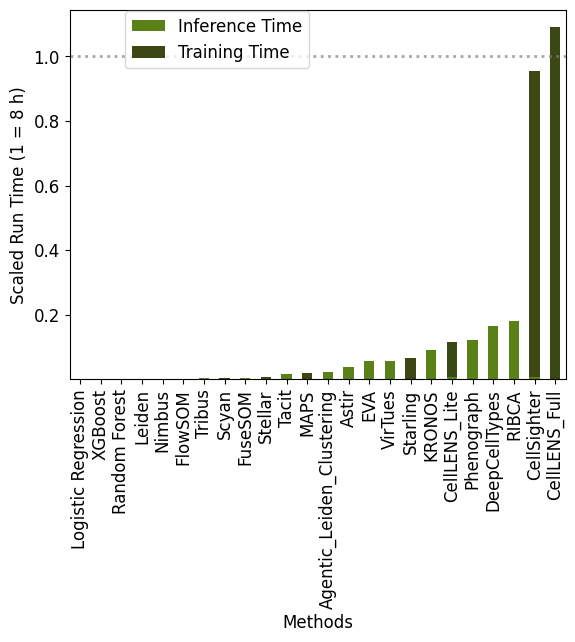

In [106]:
# Scaled run time without manual effort: train and inference time as fractions of the 8 h runtime threshold
# (runtime_thresh, the same reference as runtime_scaled / Scalability), so the stacked bar is the total run time
# and equals 1 - runtime_scaled for methods below the threshold
runtime_plot_lvl3 = scalability_plot_lvl3.copy()
runtime_plot_lvl3["run_time"] = runtime_plot_lvl3["train_time_mean"] + runtime_plot_lvl3["inference_time_mean"]

# methods without recorded times (run time 0 after fillna) would show up as fastest, so they are left out
print("no run time recorded:", runtime_plot_lvl3.loc[runtime_plot_lvl3["run_time"] == 0, "method"].tolist())
runtime_plot_lvl3 = runtime_plot_lvl3[runtime_plot_lvl3["run_time"] > 0]

runtime_plot_lvl3["train_time_scaled"] = runtime_plot_lvl3["train_time_mean"] / runtime_thresh
runtime_plot_lvl3["inference_time_scaled"] = runtime_plot_lvl3["inference_time_mean"] / runtime_thresh
runtime_plot_lvl3 = runtime_plot_lvl3.sort_values("run_time")

ax = runtime_plot_lvl3.plot.bar(
    x="method",
    y=["inference_time_scaled", "train_time_scaled"],
    stacked=True,
    color=["#598118", "#3b4814"]
)
ax.axhline(1, color="gray", linestyle=":", linewidth=2, alpha=0.7)  # runtime threshold (8 h)

# Rename legend labels
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Inference Time", "Training Time"], fontsize=12, bbox_to_anchor=(0.5, 1.02), loc='upper right')

plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
plt.xlabel("Methods")
plt.ylabel("Scaled Run Time (1 = 8 h)")
ax.grid(False)  # Remove grid lines
plt.savefig(os.path.join(output_path, "scaled_runtime_plot_lvl3.svg"), format='svg', bbox_inches='tight', dpi=300)


In [130]:
# axis scale for the three run time plots below: True = log scale, False = linear
runtime_log_scale = True
runtime_scale = "log" if runtime_log_scale else "linear"
runtime_scale_label = " (log scale)" if runtime_log_scale else ""

# run time reference lines [h]
runtime_lines_h = [0.1,1, 4, ]
runtime_lines_label = " / ".join(str(h) for h in runtime_lines_h) + " h"


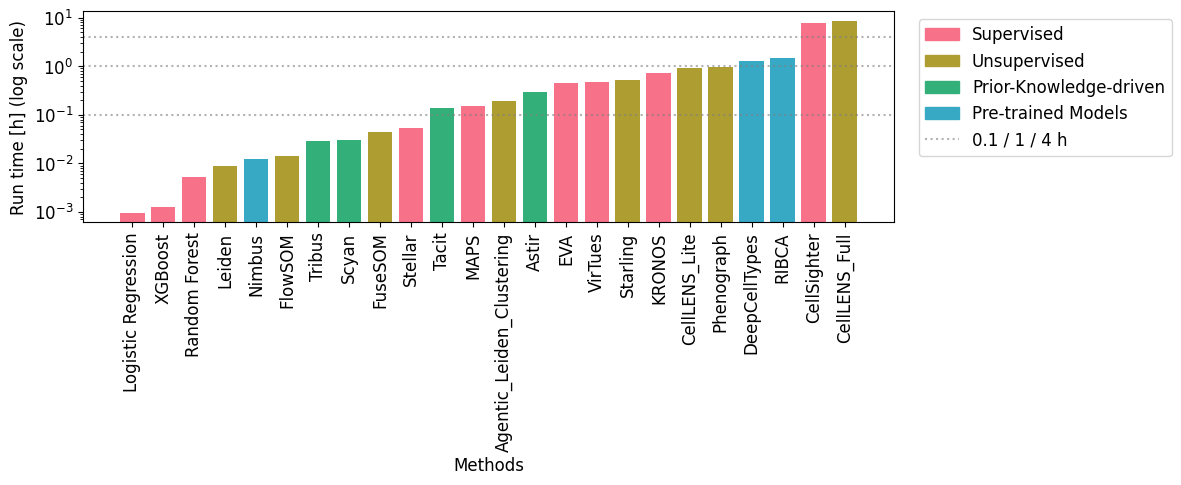

In [131]:
# Actual run time (train + inference, mean over datasets) per method in hours, log scale, colored by method group
runtime_hours = runtime_plot_lvl3["run_time"] / 3600
bar_colors = [method_cmap.get(method_to_group.get(m), "gray") for m in runtime_plot_lvl3["method"]]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(runtime_plot_lvl3["method"], runtime_hours, color=bar_colors)
for i, h in enumerate(runtime_lines_h):
    ax.axhline(h, color="gray", linestyle=":", linewidth=1.5, alpha=0.6, label=runtime_lines_label if i == 0 else None)
ax.set_yscale(runtime_scale)

# legend: method groups present in the plot + run time lines
present_groups = {method_to_group.get(m) for m in runtime_plot_lvl3["method"]}
group_handles = [mpatches.Patch(color=color, label=group) for group, color in method_cmap.items() if group in present_groups]
line_handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=group_handles + line_handles, fontsize=12, bbox_to_anchor=(1.02, 1), loc='upper left')

plt.xticks(fontsize=12, rotation=90)
plt.yticks(fontsize=12)
ax.set_xlabel("Methods")
ax.set_ylabel(f"Run time [h]{runtime_scale_label}")
ax.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(output_path, f"runtime_hours_plot_lvl3_{runtime_scale}.svg"), format='svg', bbox_inches='tight', dpi=300)
plt.show()


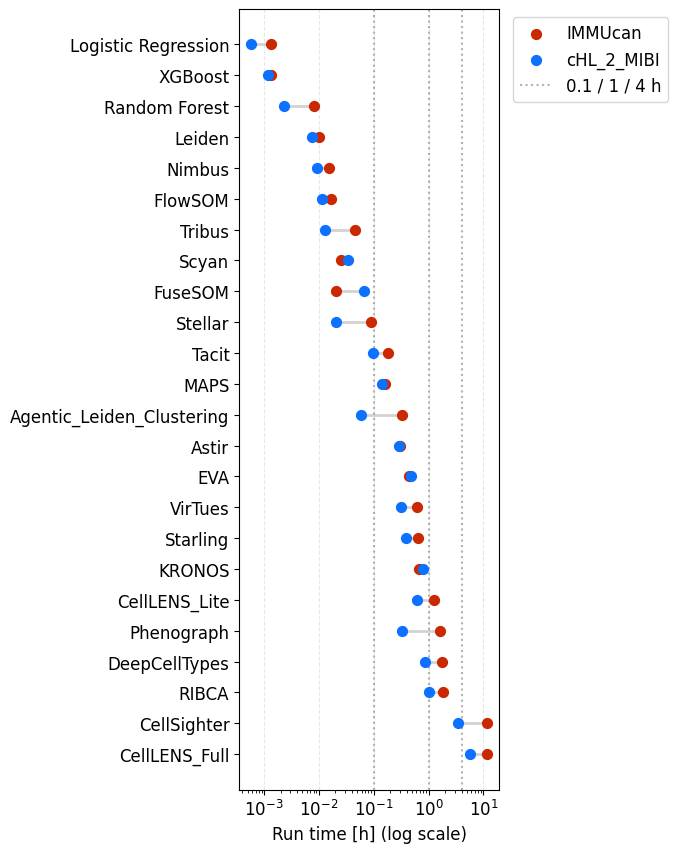

In [132]:
# Run time per dataset (no averaging over datasets): one dot per dataset, the two datasets of a method joined by a line,
# methods sorted by mean run time
runtime_per_dataset = results.loc[
    (results["level"] == "level3") & results["method"].isin(runtime_plot_lvl3["method"]),
    ["dataset", "method", "run_time"]
]
# a method without a recorded time on a dataset would show up as fastest there, so that dot is left out
runtime_per_dataset = runtime_per_dataset[runtime_per_dataset["run_time"] > 0].assign(
    run_time_h=lambda d: d["run_time"] / 3600)
method_order = runtime_per_dataset.groupby("method")["run_time_h"].mean().sort_values().index
y_pos = {m: i for i, m in enumerate(method_order)}

fig, ax = plt.subplots(figsize=(7, 0.3 * len(method_order) + 1.5))
span = runtime_per_dataset.groupby("method")["run_time_h"].agg(["min", "max"]).loc[method_order]
ax.hlines(range(len(method_order)), span["min"], span["max"], color="lightgray", linewidth=2, zorder=1)
for ds, ds_df in runtime_per_dataset.groupby("dataset"):
    ax.scatter(ds_df["run_time_h"], ds_df["method"].map(y_pos), color=to_hex(dataset_cmap[ds]), s=50, label=ds, zorder=3)
for i, h in enumerate(runtime_lines_h):
    ax.axvline(h, color="gray", linestyle=":", linewidth=1.5, alpha=0.6, label=runtime_lines_label if i == 0 else None)

ax.set_xscale(runtime_scale)
ax.set_yticks(range(len(method_order)))
ax.set_yticklabels(method_order, fontsize=12)
ax.invert_yaxis()  # fastest method on top
ax.set_xlabel(f"Run time [h]{runtime_scale_label}", fontsize=12)
ax.legend(fontsize=12, bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_path, f"runtime_per_dataset_lvl3_{runtime_scale}.svg"), format='svg', bbox_inches='tight', dpi=300)
plt.show()


                 min        50%        max
dataset                                   
IMMUcan     457117.0  2285585.0  2742702.0
cHL_2_MIBI  692667.0  1154445.0  1847112.0


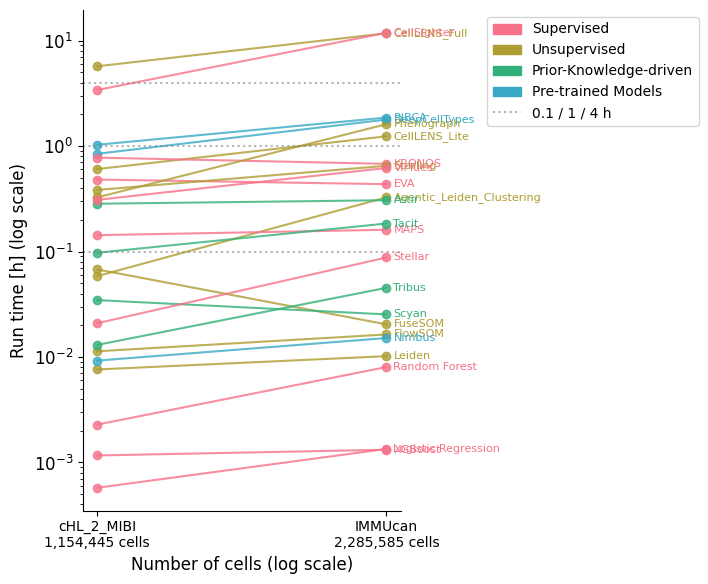

In [133]:
# Run time vs number of cells: one point per dataset, the two datasets of a method joined by a line.
# With only two datasets the slope mixes dataset size with all other dataset differences (markers, cell types, image size),
# so this is an indication, not a scaling experiment

# number of cells per dataset: every cell is in exactly one test fold, so the level3 support summed over folds and
# classes is the number of evaluated cells; methods can evaluate slightly different cell sets, so the median is used
cells_per_method = per_class_results[per_class_results["level"] == "level3"].groupby(["dataset", "method"])["support"].sum()
print(cells_per_method.groupby("dataset").describe()[["min", "50%", "max"]])
n_cells = cells_per_method.groupby("dataset").median()

runtime_vs_cells = runtime_per_dataset.assign(n_cells=runtime_per_dataset["dataset"].map(n_cells))

fig, ax = plt.subplots(figsize=(8, 6))
for method, m_df in runtime_vs_cells.groupby("method"):
    m_df = m_df.sort_values("n_cells")
    color = to_hex(method_cmap.get(method_to_group.get(method), "gray"))
    ax.plot(m_df["n_cells"], m_df["run_time_h"], marker="o", color=color, linewidth=1.5, alpha=0.8)
    ax.annotate(method, (m_df["n_cells"].iloc[-1], m_df["run_time_h"].iloc[-1]), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=8, color=color)
for i, h in enumerate(runtime_lines_h):
    ax.axhline(h, color="gray", linestyle=":", linewidth=1.5, alpha=0.6, label=runtime_lines_label if i == 0 else None)

ax.set_xscale(runtime_scale)
ax.set_yscale(runtime_scale)
ax.set_xticks(n_cells.values)
ax.set_xticklabels([f"{ds}\n{int(n):,} cells" for ds, n in n_cells.items()], fontsize=10)
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xlabel(f"Number of cells{runtime_scale_label}", fontsize=12)
ax.set_ylabel(f"Run time [h]{runtime_scale_label}", fontsize=12)

# legend: method groups present in the plot + run time lines
present_groups = {method_to_group.get(m) for m in runtime_vs_cells["method"]}
group_handles = [mpatches.Patch(color=color, label=group) for group, color in method_cmap.items() if group in present_groups]
line_handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=group_handles + line_handles, fontsize=10, bbox_to_anchor=(1.25, 1), loc='upper left')
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(output_path, f"runtime_vs_cells_lvl3_{runtime_scale}.svg"), format='svg', bbox_inches='tight', dpi=300)
plt.show()


In [103]:

methods = scalability_plot_lvl3_sorted["method"].tolist()
revised_scaling_score = scalability_plot_lvl3_sorted["revised_scaling_score"].fillna(0)
inference_time_scaled = scalability_plot_lvl3_sorted["inference_time_scaled"].fillna(0)
train_time_scaled = scalability_plot_lvl3_sorted["train_time_scaled"].fillna(0)

fig = go.Figure(data=[
    go.Bar(name='Manual Effort', x=methods, y=revised_scaling_score, marker_color='#aeb374'),
    go.Bar(name='Inference Time (scaled)', x=methods, y=inference_time_scaled, marker_color='#598118'),
    go.Bar(name='Train Time (scaled)', x=methods, y=train_time_scaled, marker_color='#3b4814')
])

fig.update_layout(
    font=dict(
        size=12,           # Default font size for all text
    ),
    xaxis=dict(
        title_font=dict(size=14),   # X-axis title font size
        tickfont=dict(size=12),     # X-axis tick label font size
    ),
    yaxis=dict(
        title_font=dict(size=14),   # Y-axis title font size
        tickfont=dict(size=12),     # Y-axis tick label font size
    ),
    title_font=dict(size=16),       # Title font size
    legend=dict(
        font=dict(size=12),         # Legend font size
        title_font=dict(size=14),   # Legend title font size
    )
)

fig.update_layout(
    barmode='stack',
    xaxis_title='Method',
    xaxis_tickangle=-45,
    yaxis_title='Scaled Value',
    title='Scalability Components by Method',
    #legend=dict(x=1.05, y=1, bordercolor="Black", borderwidth=1),
    width=650,
    height=400,
    plot_bgcolor='white',
    paper_bgcolor='white'
)
fig.show()

fig.write_html( "../website/plotly_figures/scalability_plot.html")

# save as svg
fig.write_image("../figures/new/scalability_plot.svg", width=800, height=400, scale=2)

FileNotFoundError: [Errno 2] No such file or directory: '../website/plotly_figures/scalability_plot.html'

## rare cell type analysis

In [134]:
## Run once

all_qt_path = "../all_qt/"

csv_files = sorted([f for f in os.listdir(all_qt_path) if f.endswith(".csv")])

cell_type_percent_all = {}
for file in csv_files:
    file_path = os.path.join(all_qt_path, file)
    df_tmp = pd.read_csv(file_path)
    cell_type_percent_all[file] = (
        df_tmp["cell_type"].value_counts(normalize=True).mul(100).round(4)
    )

# Optional combined table (rows = cell_type, columns = file)
cell_type_percent_table = pd.DataFrame(cell_type_percent_all).fillna(0).sort_index()

cell_type_percent_table

,Breast_Jun0524_quantification.csv,CRC_Feb2623_quantification.csv,GVHD_Feb1323_quantification.csv,IMMUcan_quantification.csv,Melanoma_Oct2522_quantification.csv,cHL_1_MIBI_quantification.csv,cHL_2_MIBI_quantification.csv,cHL_CODEX_quantification.csv,cycif_ovca_quantification.csv,feto_maternal_quantification.csv,healthy_bone_marrow_quantification.csv,myeloma_IMC_quantification.csv
cell_type,,,,,,,,,,,,
AEC,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.6401,0.0000
APC,0.0788,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Adipo-MSC,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5764,0.0000
Adipocyte,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.0121,1.1638
B_cell,1.5637,2.1956,0.6689,1.8076,4.9755,12.2084,10.4505,11.1573,0.3077,0.0000,0.0000,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...
T_cell,0.6307,1.1577,0.4459,0.0000,0.6225,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Treg,0.0000,2.1956,2.5084,2.3646,1.1979,3.7885,17.3079,2.3092,1.6992,0.0176,0.0000,0.0000
VSMC,0.0000,1.7565,0.0000,0.0000,1.3347,0.0000,0.0000,0.0000,8.6798,0.0000,0.2617,0.0000


In [135]:
# average the clustering methods per fold and class, as for results
per_class_results = average_cluster_variants(per_class_results, ["dataset", "level", "fold", "class_label"])
per_class_results["method"] = per_class_results["method"].map(rename_method)


dropped: ['FuseSOM_14_subclust6_purity0_66', 'FuseSOM_14_subclust7_purity0_66', 'flowsom_meta_clusters_subclust5_purity0_66', 'leiden_res0_5', 'leiden_res0_8', 'leiden_res2_0', 'nimbus_leiden_res2_0', 'phenograph_20', 'phenograph_30', 'phenograph_40', 'phenograph_80']
groups without single pass + 4 subclustering rounds:
 dataset     level   fold  class_label  method               
IMMUcan     level1  0.0   Cancer       CellLENS_Full            4
                                       CellLENS_Lite            4
                                       flowsom_meta_clusters    4
                          Immune       CellLENS_Full            4
                                       CellLENS_Lite            4
                                                               ..
cHL_2_MIBI  level3  5.0   Treg         CellLENS_Lite            1
                                       flowsom_meta_clusters    1
                          undefined    CellLENS_Full            1
                      

In [138]:
per_class_results["method"].unique()

array(['Agentic_Leiden_Clustering', 'Astir', 'CellSighter',
       'DeepCellTypes', 'DeepCellTypes_adapted', 'EVA', 'KRONOS',
       'Logistic Regression', 'MAPS', 'Most Frequent', 'Random Forest',
       'RIBCA', 'RIBCA_adapted', 'Scyan', 'Starling', 'Stellar',
       'Stratified sampler', 'Tacit', 'Tribus', 'VirTues', 'XGBoost',
       'CellLENS_Full', 'CellLENS_Lite', 'FuseSOM', 'FlowSOM', 'Leiden',
       'Nimbus', 'Phenograph'], dtype=object)

In [139]:
## Run once 

# Bin rules (in percent):
# >20        -> abundant
# 5 to 20    -> common
# 1 to <5    -> rare
# <1         -> ultra_rare
def abundance_bin(pct):
    if pct > 20:
        return "abundant"
    elif pct >= 5:
        return "common"
    elif pct >= 1:
        return "rare"
    else:
        return "ultra_rare"

records = []

for file in csv_files:
    dataset = file.replace("_quantification.csv", "")
    file_path = os.path.join(all_qt_path, file)

    df_tmp = pd.read_csv(file_path)
    pct = df_tmp["cell_type"].value_counts(normalize=True).mul(100)

    tmp = pct.rename_axis("cell_type").reset_index(name="abundance_pct")
    tmp["dataset"] = dataset
    tmp["abundance_bin"] = tmp["abundance_pct"].apply(abundance_bin)

    records.append(tmp)

cell_type_abundance_bins = pd.concat(records, ignore_index=True)

# Nice ordering for downstream plots/tables
bin_order = ["abundant", "common", "rare", "ultra_rare"]
cell_type_abundance_bins["abundance_bin"] = pd.Categorical(
    cell_type_abundance_bins["abundance_bin"],
    categories=bin_order,
    ordered=True
)

# Optional summary: how many cell types per bin per dataset
bin_summary = (
    cell_type_abundance_bins
    .groupby(["dataset", "abundance_bin"], observed=True)
    .size()
    .rename("n_cell_types")
    .reset_index()
)

display(cell_type_abundance_bins.sort_values(["dataset", "abundance_bin", "abundance_pct"], ascending=[True, True, False]))
display(bin_summary)

,cell_type,abundance_pct,dataset,abundance_bin
0,Cancer,35.413929,Breast_Jun0524,abundant
1,Macrophage,15.847569,Breast_Jun0524,common
2,Fibroblast,12.457293,Breast_Jun0524,common
3,CD4+_T_cell,9.408673,Breast_Jun0524,common
4,CD8+_T_cell,9.145861,Breast_Jun0524,common
...,...,...,...,...
185,Adipocyte,1.163811,myeloma_IMC,rare
186,Dendritic_cell,0.624452,myeloma_IMC,ultra_rare
187,Osteoblast,0.551141,myeloma_IMC,ultra_rare
188,Osteocyte,0.308953,myeloma_IMC,ultra_rare


,dataset,abundance_bin,n_cell_types
0,Breast_Jun0524,abundant,1
1,Breast_Jun0524,common,5
2,Breast_Jun0524,rare,4
3,Breast_Jun0524,ultra_rare,4
4,CRC_Feb2623,abundant,2
5,CRC_Feb2623,common,1
6,CRC_Feb2623,rare,9
7,CRC_Feb2623,ultra_rare,5
8,GVHD_Feb1323,abundant,1
9,GVHD_Feb1323,common,4


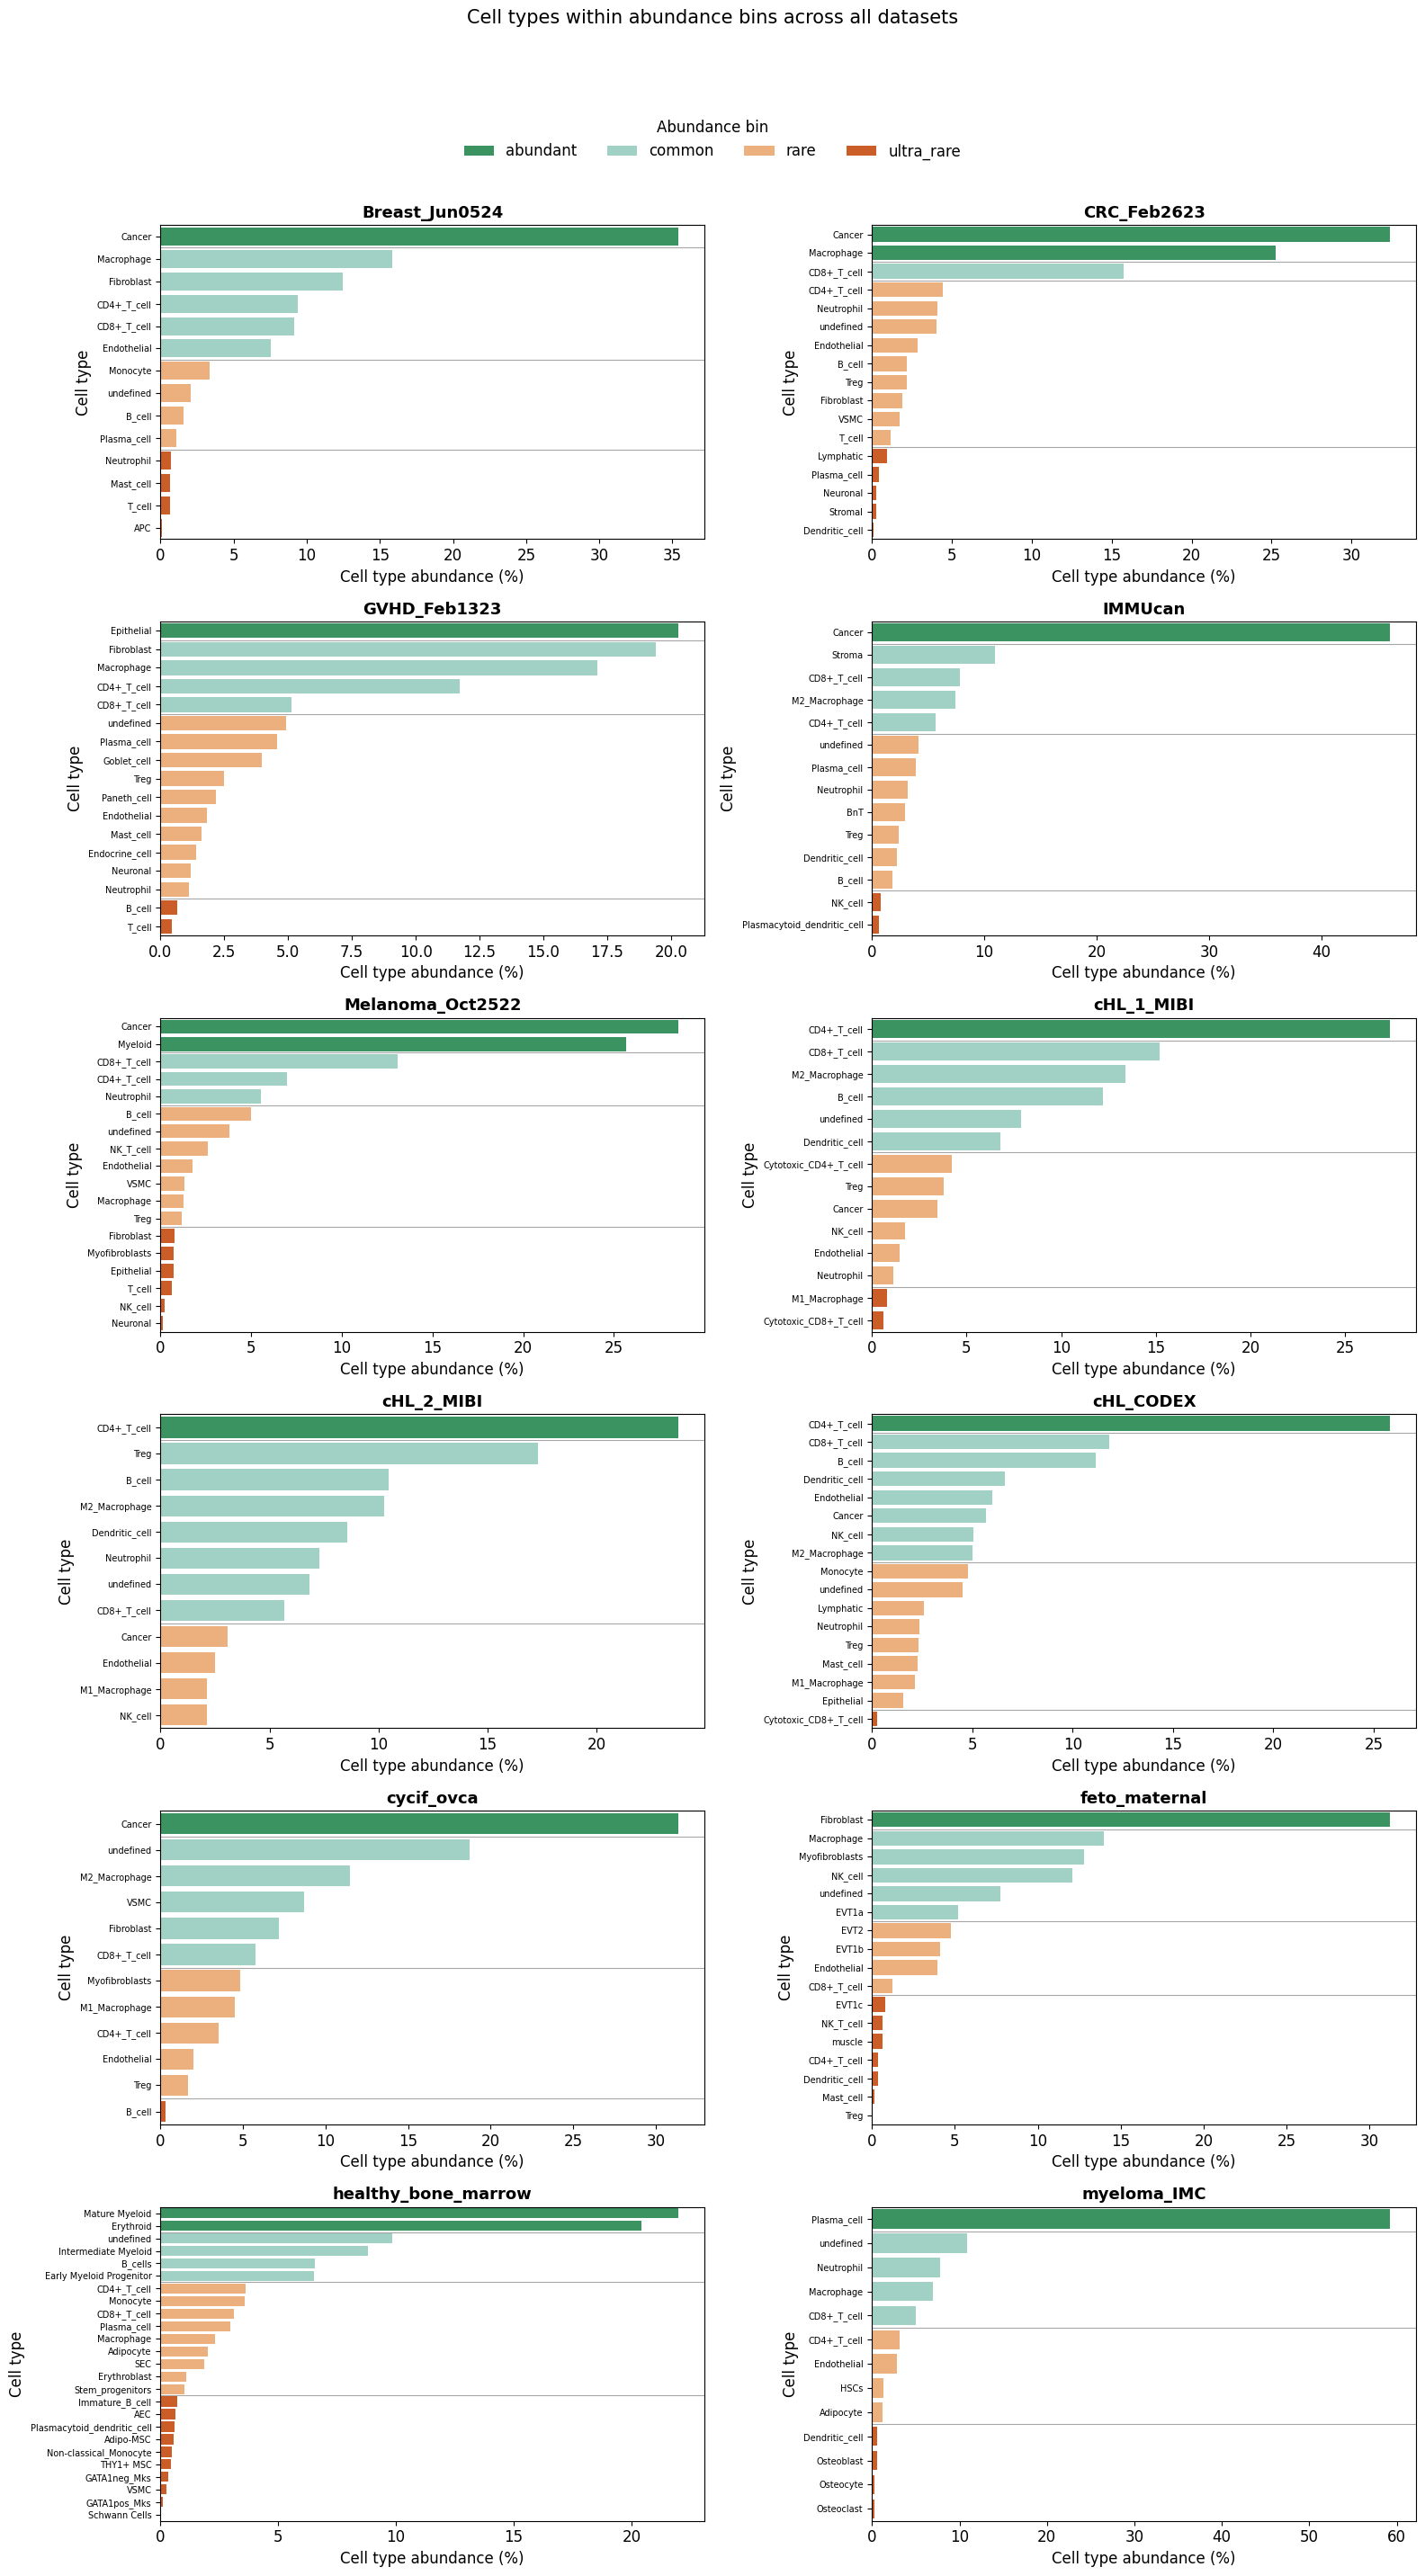

In [143]:
# Requires: cell_type_abundance_bins with columns:
# dataset, cell_type, abundance_bin, abundance_pct

bin_order = ["abundant", "common", "rare", "ultra_rare"]
bin_colors = {
    "abundant": "#2ca25f",
    "common": "#99d8c9",
    "rare": "#fdae6b",
    "ultra_rare": "#e6550d",
}

plot_df = cell_type_abundance_bins.copy()
plot_df["abundance_bin"] = pd.Categorical(
    plot_df["abundance_bin"], categories=bin_order, ordered=True
)
plot_df = plot_df.dropna(subset=["abundance_bin"])
plot_df = plot_df.sort_values(
    ["dataset", "abundance_bin", "abundance_pct"],
    ascending=[True, True, False]
)

datasets_all = sorted(plot_df["dataset"].unique())
n = len(datasets_all)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, max(6, 4.5 * nrows)),
    squeeze=False
)

for i, ds in enumerate(datasets_all):
    ax = axes.flat[i]
    ds_df = plot_df[plot_df["dataset"] == ds].copy()

    # Ordered y-axis: bins first, then abundance descending inside each bin
    y_order = ds_df.sort_values(
        ["abundance_bin", "abundance_pct"],
        ascending=[True, False]
    )["cell_type"].tolist()

    sns.barplot(
        data=ds_df,
        y="cell_type",
        x="abundance_pct",
        hue="abundance_bin",
        order=y_order,
        dodge=False,
        palette=bin_colors,
        ax=ax
    )

    # Visual separators between bins
    running = 0
    for b in bin_order:
        count_b = (ds_df["abundance_bin"] == b).sum()
        running += count_b
        if running < len(ds_df):
            ax.axhline(running - 0.5, color="black", linewidth=0.8, alpha=0.35)

    ax.set_title(ds, fontsize=13, fontweight="bold")
    ax.set_xlabel("Cell type abundance (%)")
    ax.set_ylabel("Cell type")
    ax.tick_params(axis="y", labelsize=7)

    if ax.get_legend() is not None:
        ax.get_legend().remove()

# Remove empty axes if dataset count is odd
for j in range(n, nrows * ncols):
    fig.delaxes(axes.flat[j])

# Single shared legend
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    title="Abundance bin",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=len(bin_order),
    frameon=False
)

plt.suptitle("Cell types within abundance bins across all datasets", y=1.06, fontsize=15)
plt.tight_layout()

plt.savefig(os.path.join(output_path, f"celltype_abundance_bins.svg"), format='svg', bbox_inches='tight', dpi=400)


plt.show()

In [144]:
from sklearn.metrics import f1_score

def f1_by_abundance_bin(eval_df, dataset_name, bins_df):
    """
    eval_df needs: true_phenotype, predicted_phenotype
    bins_df is cell_type_abundance_bins from the previous cell
    """
    dmap = bins_df[bins_df["dataset"] == dataset_name][["cell_type", "abundance_bin"]].copy()

    work = eval_df.merge(
        dmap.rename(columns={"cell_type": "true_phenotype"}),
        on="true_phenotype",
        how="left"
    )

    work["abundance_bin"] = work["abundance_bin"].fillna("unknown")

    out = (
        work.groupby("abundance_bin", dropna=False)
        .apply(lambda g: f1_score(g["true_phenotype"], g["predicted_phenotype"], average="weighted"))
        .rename("f1_weighted")
        .reset_index()
    )

    return out.sort_values("abundance_bin")

In [145]:
# expects cell_type_abundance_bins from your earlier abundance-bin cell
# columns needed there: dataset, cell_type, abundance_bin, abundance_pct

bin_map = (
    cell_type_abundance_bins[["dataset", "cell_type", "abundance_bin", "abundance_pct"]]
    .drop_duplicates()
    .rename(columns={"cell_type": "class_label"})
)

per_class_fold_metrics_bin = per_class_results.merge(
    bin_map, on=["dataset", "class_label"], how="left"
)
per_class_fold_metrics_bin["abundance_bin"] = per_class_fold_metrics_bin["abundance_bin"]

# weighted fold-level summary by abundance bin (weights = class support)
def weighted_avg(g, col):
    w = g["support"].values
    x = g[col].values
    if w.sum() == 0:
        return np.nan
    return np.average(x, weights=w)

fold_bin_metrics = (
    per_class_fold_metrics_bin
    .groupby(["dataset", "level", "method", "fold", "abundance_bin"], as_index=False)
    .apply(lambda g: pd.Series({
        "precision": weighted_avg(g, "precision"),
        "recall": weighted_avg(g, "recall"),
        "f1": weighted_avg(g, "f1"),
        "n_cells": g["support"].sum(),
        "n_classes": g["class_label"].nunique()
    }))
    .reset_index(drop=True)
)

# mean across folds for each method and abundance bin
method_bin_mean = (
    fold_bin_metrics
    .groupby(["dataset", "level", "method", "abundance_bin"], as_index=False)[["precision", "recall", "f1"]]
    .mean()
)

# # save
# per_class_fold_metrics_bin.to_csv(f"per_class_fold_metrics_{dataset_name}_{level_name}.csv", index=False)
# fold_bin_metrics.to_csv(f"fold_bin_metrics_{dataset_name}_{level_name}.csv", index=False)
# method_bin_mean.to_csv(f"method_bin_mean_{dataset_name}_{level_name}.csv", index=False)

# print("Saved:")
# print(f"  per_class_fold_metrics_{dataset_name}_{level_name}.csv")
# print(f"  fold_bin_metrics_{dataset_name}_{level_name}.csv")
# print(f"  method_bin_mean_{dataset_name}_{level_name}.csv")

/tmp/ipykernel_3060134/408183385.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per_class_fold_metrics_bin
/tmp/ipykernel_3060134/408183385.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({
/tmp/ipykernel_3060134/408183385.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fold_bi

In [ ]:
method_bin_mean

/tmp/ipykernel_3060134/2355045367.py:16: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  method_bin_mean[


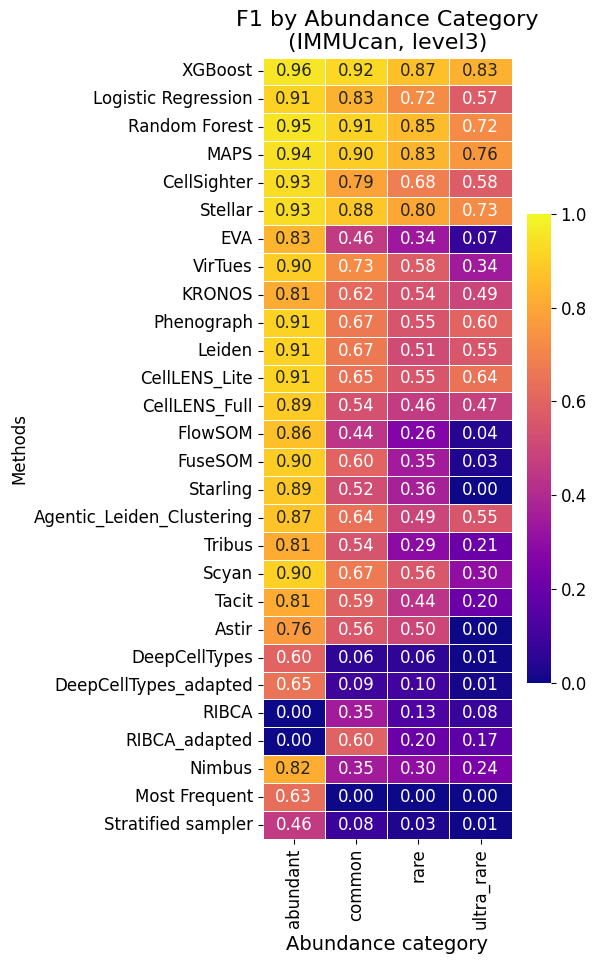

/tmp/ipykernel_3060134/2355045367.py:16: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  method_bin_mean[


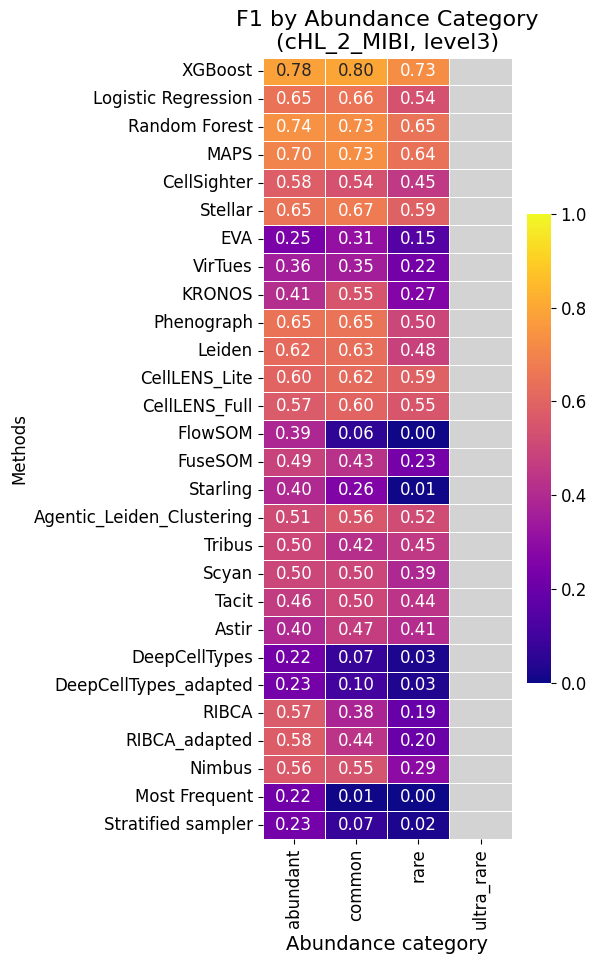

In [152]:
# Keep your preferred grouping/order here
method_groups = {
    "Supervised": ["XGBoost", "Logistic Regression", "Random Forest", "MAPS", "CellSighter", "Stellar", "EVA", "VirTues", "KRONOS"],
    "Unsupervised": ["Phenograph", "Leiden", "CellLENS_Lite", "CellLENS_Full",
                     "FlowSOM", "FlowSOM_Meta_Clusters", "FuseSOM", "Starling", "Agentic_Leiden_Clustering"],
    "Prior-Knowledge-driven": ["Tribus", "Scyan", "Tacit", "Astir"],
    "Pre-trained Models": ["DeepCellTypes", "DeepCellTypes_adapted", "RIBCA", "RIBCA_adapted", "Nimbus"],
    "Baselines": ["Most Frequent", "Stratified sampler"],
}

level_name = "level3"
order = ["abundant", "common", "rare", "ultra_rare"]

for ds in ["IMMUcan", "cHL_2_MIBI"]:
    heat = (
        method_bin_mean[
            (method_bin_mean["dataset"] == ds) &
            (method_bin_mean["level"] == level_name) &
            (method_bin_mean["abundance_bin"].isin(order))
        ]
        .pivot_table(index="method", columns="abundance_bin", values="f1", aggfunc="mean")
        .reindex(columns=order)
        .dropna(how="all")
    )

    # order the method names by method groups and then by the order in the heatmap
    method_order = []
    for group in method_groups.values():
        for method in group:
            if method in heat.index:
                method_order.append(method)
    heat = heat.reindex(index=method_order)

    plt.figure(figsize=(6, max(4, 0.35 * len(heat))))
    ax = sns.heatmap(heat, annot=True, fmt=".2f", cmap="plasma", vmin=0, vmax=1,
                     cbar_kws={"shrink": .6}, annot_kws={"size": 12}, linewidths=.6)
    ax.set_facecolor("lightgray")  # empty cells: no F1 for this method and abundance category
    plt.title(f"F1 by Abundance Category\n({ds}, {level_name})", fontsize=16)
    plt.xlabel("Abundance category", fontsize=14)
    plt.ylabel("Methods")
    plt.xticks(fontsize=12, rotation=90)
    plt.yticks(fontsize=12)
    plt.tight_layout()
    
    # save the heatmaps as svg
    plt.savefig(os.path.join(output_path, f"heatmap_f1_{ds}.svg"), format='svg', bbox_inches='tight', dpi=300)
    
    plt.show()

    

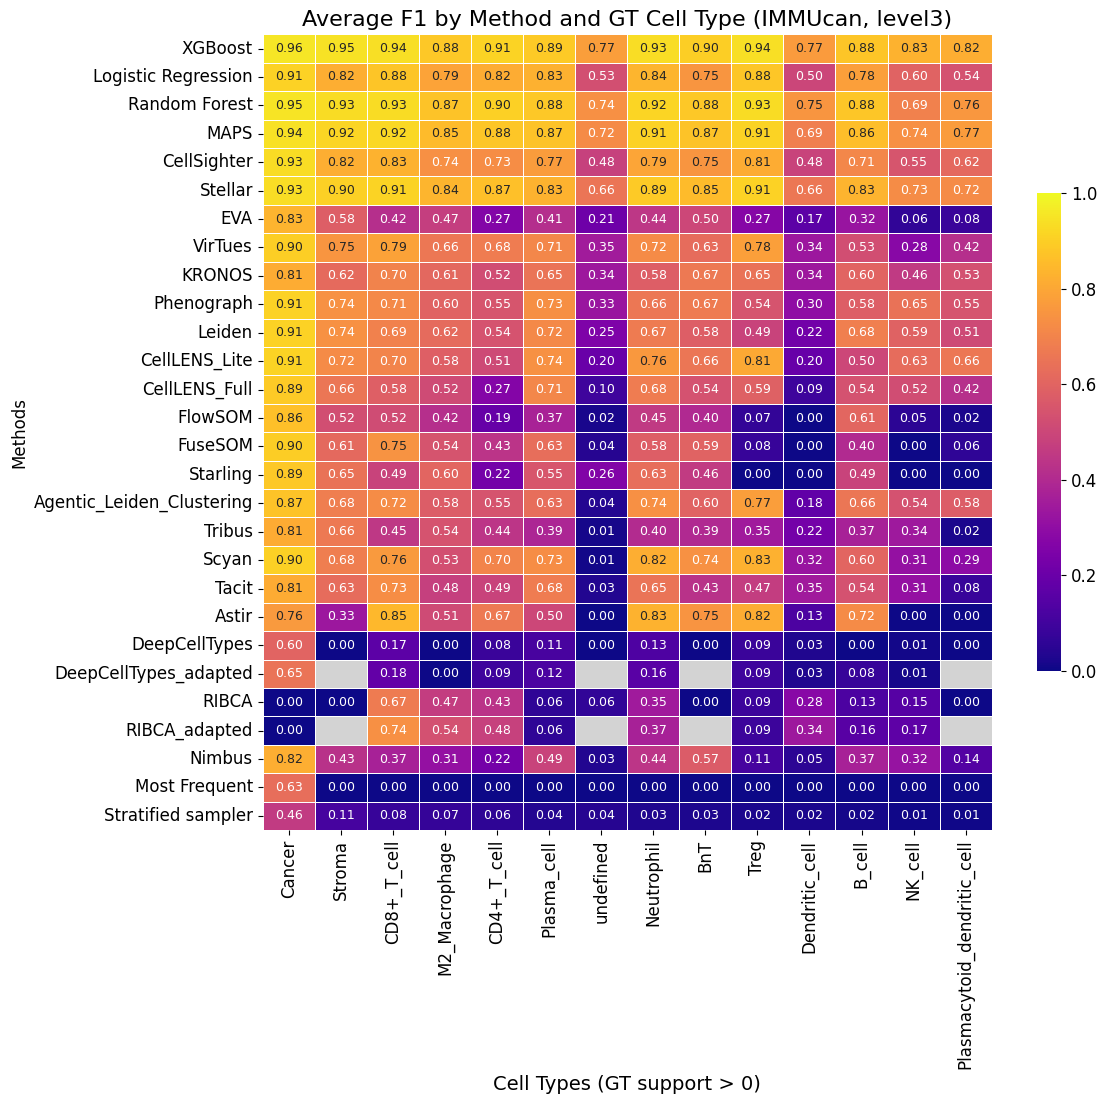

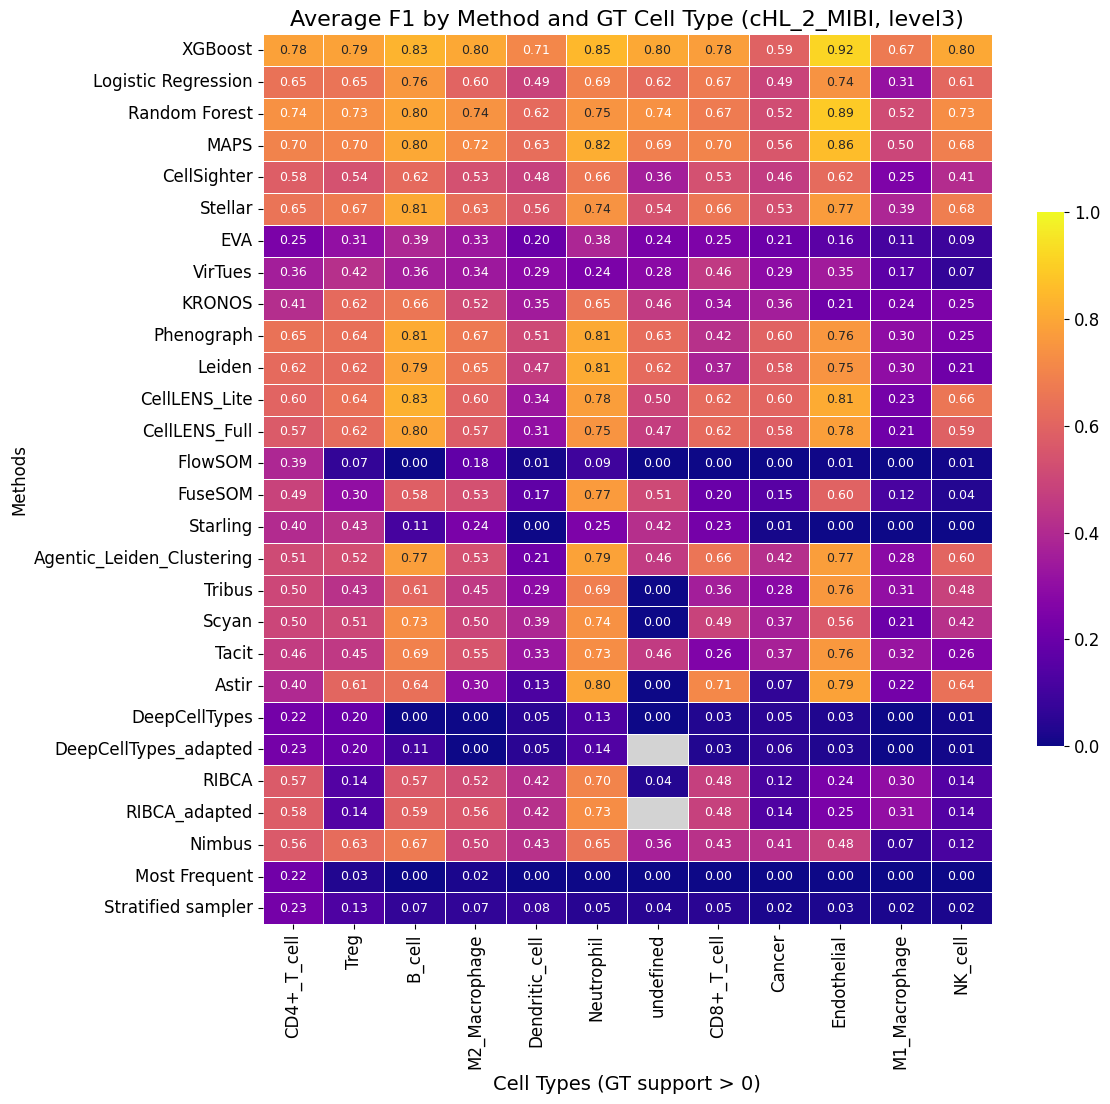

No GT-positive cell types for avg_score (level3)


In [153]:
# Keep your preferred grouping/order here
# method_groups = {
#     "Supervised": ["XGBoost", "Logistic Regression", "Random Forest", "MAPS", "CellSighter"],
#     "Unsupervised": [
#         "Phenograph", "Leiden", "CellLENS_Lite", "CellLENS_Full",
#         "FlowSOM", "FlowSOM Meta Clusters", "FuseSOM", "Starling"
#     ],
#     "Prior-Knowledge-driven": ["Tribus", "Scyan", "Tacit", "Astir"],
#     "Pre-trained Models": ["Deepcelltypes", "Deepcelltypes_adapted", "RIBCA", "RIBCA_adapted", "Nimbus"],
#     "Baselines": ["Most Frequent", "Stratified sampler"]
# }

# plot both datasets
for ds in datasets:
    # choose level to plot
    level_to_plot = "level3"  # change if needed

    ds_df = per_class_results[
        (per_class_results["dataset"] == ds) &
        (per_class_results["level"] == level_to_plot)
    ].copy()

    # 1) GT support per cell type (dataset-specific), keep only support > 0
    gt_support = ds_df.groupby("class_label", as_index=True)["support"].sum()
    gt_support = gt_support[gt_support > 0]

    # skip if nothing to plot
    if gt_support.empty:
        print(f"No GT-positive cell types for {ds} ({level_to_plot})")
        continue

    # 2) method x celltype matrix (mean F1 across folds), restricted to GT-present celltypes
    heat_df = (
        ds_df[ds_df["class_label"].isin(gt_support.index)]
        .groupby(["method", "class_label"], as_index=False)["f1"]
        .mean()
        .pivot(index="method", columns="class_label", values="f1")
    )

    # 3) order celltypes by GT prevalence
    gt_celltype_order = gt_support.sort_values(ascending=False).index.tolist()
    heat_df = heat_df.reindex(columns=[c for c in gt_celltype_order if c in heat_df.columns])

    # 4) order methods by method_groups, then append any not listed
    ordered_methods = [m for grp in method_groups.values() for m in grp if m in heat_df.index]
    ordered_methods += [m for m in heat_df.index if m not in ordered_methods]
    heat_df = heat_df.reindex(ordered_methods)

    # 5) plot
    plt.figure(figsize=(max(12, 0.6 * heat_df.shape[1]), max(6, 0.4 * heat_df.shape[0])))
    ax = sns.heatmap(
        heat_df,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 9},
        cmap="plasma",
        vmin=0,
        vmax=1,
        cbar_kws={"shrink": .6},
        linewidths=.6
    )
    ax.set_facecolor("lightgray")  # empty cells: no F1 for this method and cell type
    plt.title(f"Average F1 by Method and GT Cell Type ({ds}, {level_to_plot})", fontsize=16)
    plt.xlabel("Cell Types (GT support > 0)", fontsize=14)
    plt.ylabel("Methods")
    plt.xticks(fontsize=12, rotation=90)
    plt.yticks(fontsize=12)
    plt.tight_layout()
    # save the heatmaps as svg
    plt.savefig(os.path.join(output_path, f"f1_by_celltype_{ds}.svg"), format='svg', bbox_inches='tight', dpi=300)
    
    plt.show()

## clustering analysis

In [154]:
datasets = ["IMMUcan", "cHL_2_MIBI"]

path = "../results/"

for ds in datasets:
    file = "clusters_results.csv"
    df = pd.read_csv(os.path.join(path, ds, file))
    merged_results = []
    for ds in datasets:
        file = "clusters_results.csv"
        df = pd.read_csv(os.path.join(path, ds, file))
        df['dataset'] = ds
        merged_results.append(df)

merged_results = pd.concat(merged_results, ignore_index=True)

cluster_denominators = {
    "IMMUcan": 14,
    "cHL_2_MIBI": 12
}

merged_results["cluster_ratio"] = (
    merged_results["n_clusters"] / merged_results["dataset"].map(cluster_denominators)
)

merged_results

,method,f1_weighted_level1,f1_weighted_level2,f1_weighted_level3,f1_macro_level1,f1_macro_level2,f1_macro_level3,method_folder,n_clusters,purity,entropy,n_clusters_std,purity_std,entropy_std,n_runs,dataset,cluster_ratio
0,CellLENS_Full,0.751926,0.718137,0.595850,0.546051,0.534620,0.391943,CellLENS_Full,99.250000,0.645841,1.043311,8.808140,0.035496,0.069583,4,IMMUcan,7.089286
1,CellLENS_Full_subclust1_purity0_66,0.838329,0.801099,0.721211,0.642891,0.636778,0.562879,CellLENS_Full_subclust1_purity0_66,398.000000,0.741894,1.258375,31.224990,0.023585,0.107353,3,IMMUcan,28.428571
2,CellLENS_Full_subclust2_purity0_66,0.854187,0.822929,0.755131,0.675349,0.673266,0.610344,CellLENS_Full_subclust2_purity0_66,1113.000000,0.771556,1.441053,107.512790,0.013822,0.056341,3,IMMUcan,79.500000
3,CellLENS_Full_subclust3_purity0_66,0.860543,0.831369,0.770160,0.690549,0.689328,0.635146,CellLENS_Full_subclust3_purity0_66,2395.666667,0.784734,1.505976,326.699148,0.010453,0.052344,3,IMMUcan,171.119048
4,CellLENS_Full_subclust4_purity0_66,0.863875,0.836090,0.778116,0.698287,0.697976,0.648370,CellLENS_Full_subclust4_purity0_66,3739.333333,0.792019,1.513505,671.076995,0.008975,0.050298,3,IMMUcan,267.095238
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,phenograph_50_subclust2_k25_purity0_66,0.876950,0.822393,0.651681,0.469490,0.738136,0.605590,phenograph_50_subclust2_k25_purity0_66,1701.400000,0.658660,1.805287,63.240019,0.000790,0.008733,5,cHL_2_MIBI,141.783333
91,phenograph_50_subclust3_k25_purity0_66,0.880885,0.833483,0.671803,0.476804,0.753610,0.627788,phenograph_50_subclust3_k25_purity0_66,4257.200000,0.677976,1.674520,128.117914,0.001278,0.004822,5,cHL_2_MIBI,354.766667
92,phenograph_50_subclust4_k25_purity0_66,0.881665,0.836859,0.679272,0.478099,0.757449,0.635216,phenograph_50_subclust4_k25_purity0_66,5757.200000,0.685082,1.612293,181.316574,0.001630,0.004802,5,cHL_2_MIBI,479.766667
93,phenograph_80,0.845046,0.745149,0.545035,0.417430,0.631931,0.473610,phenograph_80,32.200000,0.554880,1.898813,1.303840,0.007075,0.028023,5,cHL_2_MIBI,2.683333


In [ ]:
merged_results

In [155]:
clustering_methods = [
    "celllens",
    "CellLENS",
    "FuseSOM",
    "leiden",
    "nimbus",
    "phenograph",
    "starling",
    "flowsom"
]

# for method in merged_results remove the strings after the first underscore
def clean_method_name(name):
    for m in clustering_methods:
        if name.lower().startswith(m.lower()):
            return m
    return name

merged_results["method"] = merged_results["method"].apply(clean_method_name)

# group by method and dataset and take the mean of the metrics
grouped_results = (
    merged_results
    .groupby([ "method_folder"], as_index=False)
    .agg({
        "f1_weighted_level3": "mean",
        "f1_macro_level3": "mean",
        "n_clusters": "mean",
        "purity": "mean",
        "entropy": "mean",
        "cluster_ratio": "mean"
    })
)

grouped_results

,method_folder,f1_weighted_level3,f1_macro_level3,n_clusters,purity,entropy,cluster_ratio
0,CellLENS_Full,0.551430,0.438198,66.625000,0.587100,1.470516,4.961310
1,CellLENS_Full_subclust1_purity0_66,0.656433,0.568932,315.900000,0.668677,1.595189,23.955952
2,CellLENS_Full_subclust2_purity0_66,0.688638,0.609087,1031.400000,0.698212,1.675428,79.325000
3,CellLENS_Full_subclust3_purity0_66,0.705307,0.630281,2451.833333,0.713948,1.675829,190.059524
4,CellLENS_Full_subclust4_purity0_66,0.715425,0.642908,4020.966667,0.723711,1.646580,312.822619
5,CellLENS_Lite,0.599530,0.497529,89.900000,0.628598,1.299397,6.732143
6,CellLENS_Lite_subclust1_purity0_66,0.682825,0.608203,374.900000,0.694223,1.498607,28.480952
7,CellLENS_Lite_subclust2_purity0_66,0.714173,0.648311,1203.200000,0.722969,1.568055,92.808333
8,CellLENS_Lite_subclust3_purity0_66,0.730853,0.670016,2696.800000,0.738437,1.542960,209.801190
9,CellLENS_Lite_subclust4_purity0_66,0.739538,0.680409,4040.100000,0.746660,1.505647,315.527381


In [156]:
grouped_results.to_csv("../final_results/cluster_results_summary.csv", index=False)

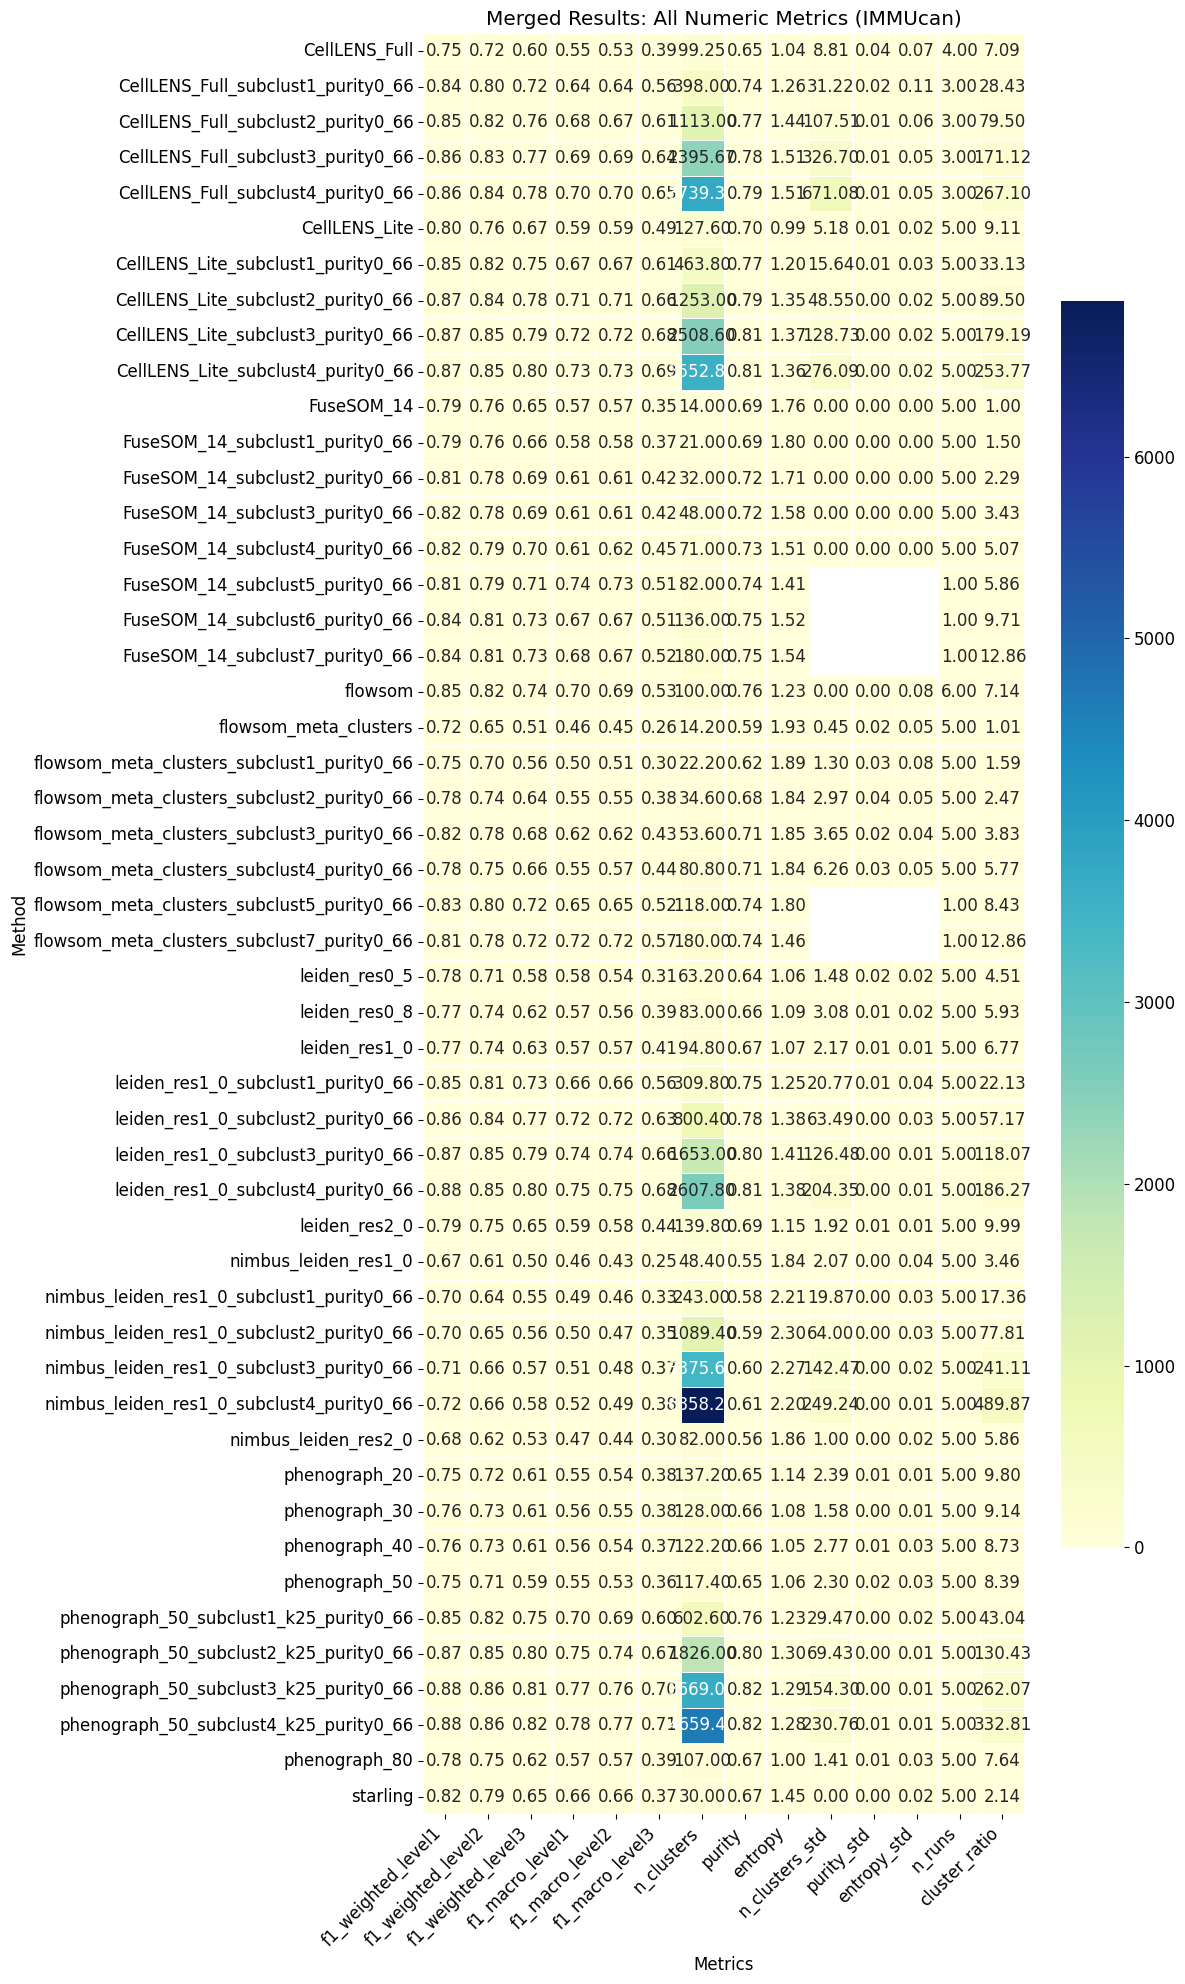

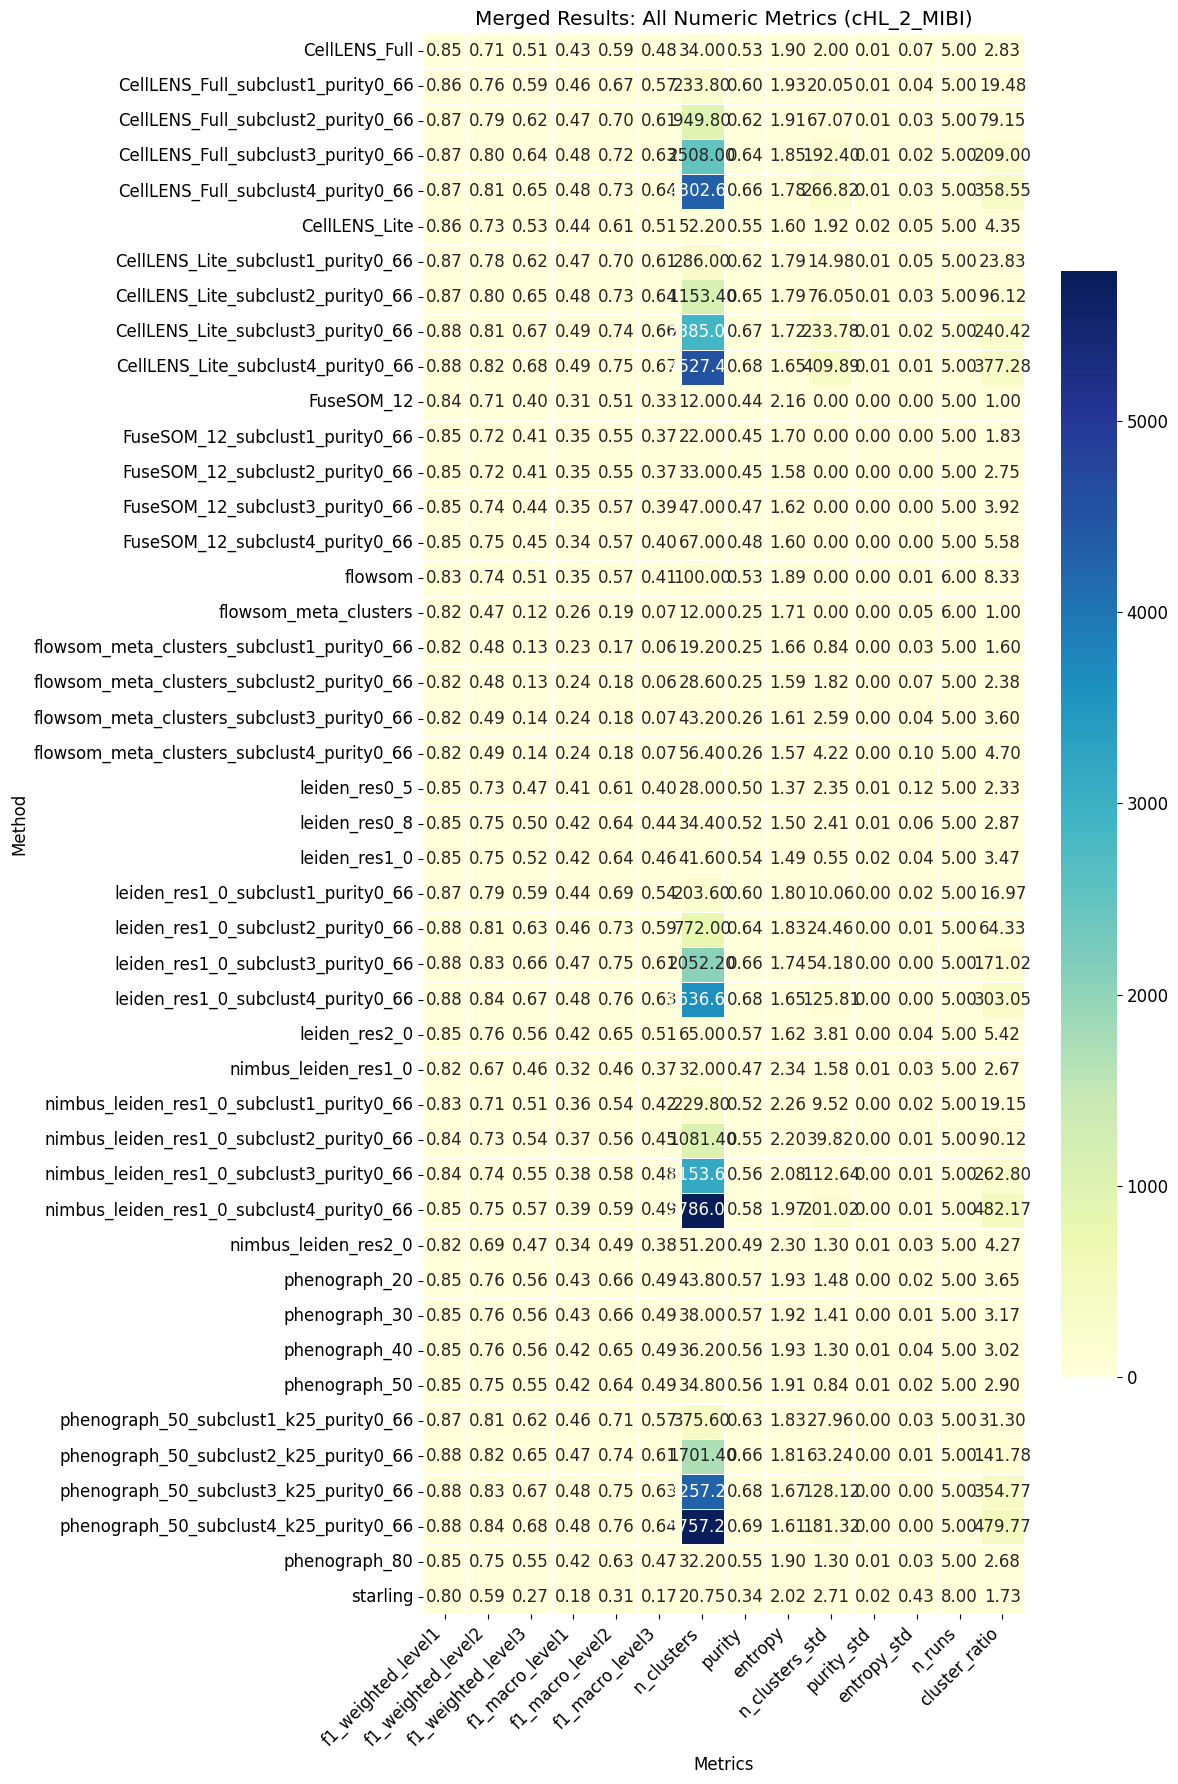

In [157]:
# Heatmap of all numeric metrics in merged_results (averaged per dataset/method_folder)
metric_cols = merged_results.select_dtypes(include=[np.number]).columns.tolist()

heat_df = (
    merged_results
    .groupby(["dataset", "method_folder"], as_index=False)[metric_cols]
    .mean()
    .set_index(["dataset", "method_folder"])
)

# Split by dataset and plot separately
datasets_list = heat_df.index.get_level_values("dataset").unique()

for ds in datasets_list:
    heat_ds = heat_df.loc[ds]
    
    plt.figure(figsize=(12, max(6, 0.4 * len(heat_ds))))
    sns.heatmap(
        heat_ds,
        cmap="YlGnBu",
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        cbar_kws={"shrink": 0.7}
    )
    
    plt.title(f"Merged Results: All Numeric Metrics ({ds})")
    plt.xlabel("Metrics")
    plt.ylabel("Method")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    #plt.savefig(os.path.join(output_path, f"clustering_metrics_{ds}.svg"), format='svg', bbox_inches='tight', dpi=300)
    plt.show()

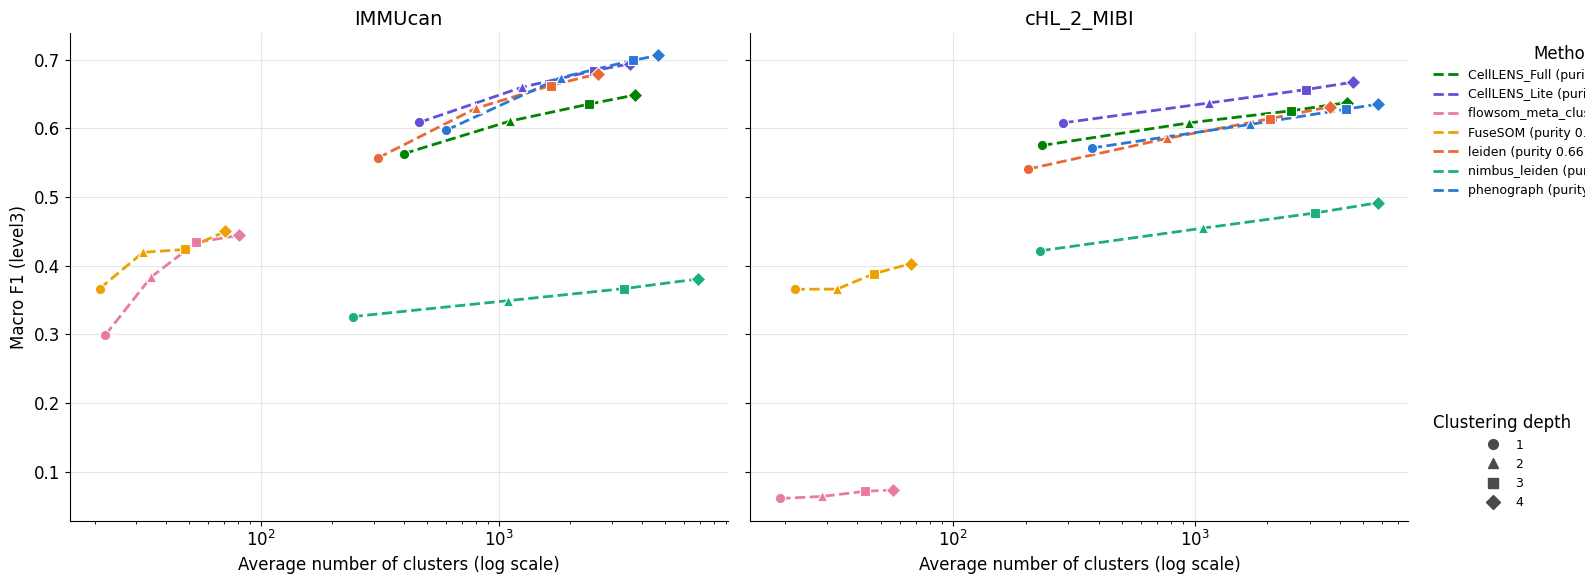

In [164]:
import re
from matplotlib.lines import Line2D

# Macro F1 vs number of clusters for the subclustering results; the subclustering steps of one method are
# joined by a line (solid: plain subclustering, dashed: subclustering with a purity threshold),
# the marker shows the clustering depth (subclustering round 1-4)
subclust_path = "../results/"
subclust_datasets = ["IMMUcan", "cHL_2_MIBI"]
level = "level3"  # level of the macro F1 from final_results.csv
f1_col = f"f1_macro_{level}"
max_depth = 4

subclust_results = pd.concat(
    [pd.read_csv(os.path.join(subclust_path, ds, "clusters_results.csv")).assign(dataset=ds) for ds in subclust_datasets],
    ignore_index=True)

def method_base(name):
    """Method without its parameters: phenograph_50_subclust2_k25_purity0_75 -> phenograph."""
    name = re.sub(r"_(subclust\d+|k\d+|purity\d+_\d+)", "", name)
    tokens = name.split("_")
    while len(tokens) > 1 and re.fullmatch(r"(res)?\d+", tokens[-1]):
        tokens.pop()
    return "_".join(tokens)

def subclust_variant(name):
    """'purity 0.75' for *_purity0_75 folders, 'plain' otherwise."""
    m = re.search(r"_purity(\d+)_(\d+)", name)
    return f"purity {m.group(1)}.{m.group(2)}" if m else "plain"

# only the subclustering rounds (*_subclust*) up to max_depth, not the single-pass results
plot_df = subclust_results[subclust_results["method_folder"].str.contains("_subclust")]
plot_df = plot_df.dropna(subset=["n_clusters", f1_col]).copy()
plot_df["depth"] = plot_df["method_folder"].str.extract(r"_subclust(\d+)", expand=False).astype(int)
plot_df = plot_df[plot_df["depth"] <= max_depth].copy()
plot_df["base"] = plot_df["method_folder"].apply(method_base)
plot_df["variant"] = plot_df["method_folder"].apply(subclust_variant)
plot_df["family"] = np.where(plot_df["variant"] == "plain", plot_df["base"],
                             plot_df["base"] + " (" + plot_df["variant"] + ")")

# one color per base method (fixed across both datasets and variants), line style per variant, marker per depth
bases = sorted(plot_df["base"].unique(), key=str.lower)
base_colors = {b: cluster_colors[b] for b in bases}
family_info = plot_df.drop_duplicates("family").set_index("family")
family_order = sorted(family_info.index, key=lambda f: (family_info.at[f, "base"].lower(), f))
family_colors = {f: base_colors[family_info.at[f, "base"]] for f in family_order}
family_linestyles = {f: "-" if family_info.at[f, "variant"] == "plain" else "--" for f in family_order}
depth_markers = {1: "o", 2: "^", 3: "s", 4: "D"}

plot_datasets = list(plot_df["dataset"].unique())
fig, axes = plt.subplots(1, len(plot_datasets), figsize=(8 * len(plot_datasets), 6), sharey=True, squeeze=False)

for ax, ds in zip(axes[0], plot_datasets):
    ds_df = plot_df[plot_df["dataset"] == ds]
    for family in family_order:
        sub = ds_df[ds_df["family"] == family].sort_values("n_clusters")
        if sub.empty:
            continue
        ax.plot(sub["n_clusters"], sub[f1_col], linestyle=family_linestyles[family], linewidth=2,
                color=family_colors[family])
        for depth, depth_sub in sub.groupby("depth"):
            ax.scatter(depth_sub["n_clusters"], depth_sub[f1_col], marker=depth_markers[depth], s=55,
                       color=family_colors[family], edgecolor="white", linewidth=0.8, zorder=3)

    ax.set_xscale("log")
    ax.set_xlabel("Average number of clusters (log scale)", fontsize=12)
    ax.set_title(ds, fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

axes[0][0].set_ylabel(f"Macro F1 ({level})", fontsize=12)
family_handles = [Line2D([], [], color=family_colors[f], linestyle=family_linestyles[f], linewidth=2, label=f)
                  for f in family_order]
depth_handles = [Line2D([], [], color="#4a4a4a", marker=m, linestyle="none", markersize=7, label=str(d))
                 for d, m in depth_markers.items()]
family_legend = axes[0][-1].legend(handles=family_handles, title="Method", loc="upper left",
                                   bbox_to_anchor=(1.02, 1), fontsize=9, frameon=False)
axes[0][-1].add_artist(family_legend)
axes[0][-1].legend(handles=depth_handles, title="Clustering depth", loc="lower left",
                   bbox_to_anchor=(1.02, 0), fontsize=9, frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(output_path, f"clusters_vs_macro_f1_{level}_subclustering.svg"), format="svg", bbox_inches="tight", dpi=300)
plt.show()


In [ ]:
plot_df.groupby(["dataset", "family"])["method_folder"].unique()
